# 0. Project Overview – Student Performance Analysis

## Summary

An analysis of 633 students taking the Portuguese language course at two Portuguese secondary schools (after removing 16 students with a zero grade, most of whom missed the final exam).

- **Mid-year grades dominate ([Q2](#q2-once-past-grades-are-known-what-still-carries-signal)):** `G1` and `G2` explain $88\%$ of the variance of the final grade (`G3`). Once they are known, no other factor adds statistically significant information.
- **Past failures are the strongest early warning sign ([Q1](#q1-which-single-factors-matter-most)):** they explain $18\%$ of the variance of the final grade ($\rho=-0.43$), followed by plans for higher education and the mother's education level. Together with the school, past failures separate passing from failing students best (AUC $=0.78$, [Q3](#q3-which-pairs-of-factors-best-separate-passing-from-failing-students)).
- **Background factors alone explain about $30\%$:** without any grades, all other factors together explain $27$–$31\%$ of the variance of the final grade, which is enough for a start-of-year early warning signal.
- **The two schools differ sharply:** $25.5\%$ of Mousinho da Silveira students fail, compared with $7.4\%$ at Gabriel Pereira, and 14 of the 15 students who missed the final exam were from Mousinho da Silveira.
- **School support and paid classes ([Q4](#q4-do-paid-classes-or-school-support-help)):** students who receive them score slightly lower, but they also started the year with lower grades, so this data cannot show whether support works.

All findings are associations found in survey data, not causal effects.

## The Goal of the Project

Using a rich real-world dataset on student performance, we investigate which _factors and combinations of factors_ are associated with students' academic performance. The project is meant for teenagers who would rather be understood than judged, teachers and tutors who want to understand their students better, administrators accountable for pass rates, and parents who want to support their children.

## Main Questions to Answer

[__*Q1.*__](#q1-which-single-factors-matter-most) Excluding prior grades, which single factor is most strongly associated with the final grade?
[__*Q2.*__](#q2-once-past-grades-are-known-what-still-carries-signal) Once past performance (`G1` and `G2`) is taken into account, which factors still carry any signal for the final grade (`G3`)?
[__*Q3.*__](#q3-which-pairs-of-factors-best-separate-passing-from-failing-students) Which pair of factors best separates students who pass from those who fail?
[__*Q4.*__](#q4-do-paid-classes-or-school-support-help) How strongly are school support and paid extra classes related to outcomes?

## The Data

This project uses the [Student Alcohol Consumption](https://www.kaggle.com/datasets/uciml/student-alcohol-consumption?select=student-por.csv) datasets published on Kaggle by [UCI Machine Learning](https://www.kaggle.com/organizations/uciml) and [Dmitrii Batogov](https://www.kaggle.com/dmitriy19). The data were originally collected by P. Cortez and A. Silva (*Using Data Mining to Predict Secondary School Student Performance*, 2008) from school reports and questionnaires of secondary school students taking Mathematics and Portuguese language courses ([original source](https://archive.ics.uci.edu/dataset/320/student+performance)). This project focuses on the Portuguese language dataset because it covers more students (649 vs 395), which gives the statistical tests more power.

## Project Structure

The project consists of 5 parts:
1. [Preliminaries](#1-preliminaries)
Understanding the data and imports.
2. [Initial EDA and Data Cleaning](#2-initial-eda-and-data-cleaning)
Missing values, duplicates, outliers and the decision to drop students with zero grades.
3. [Data Exploration](#3-data-exploration-continue-eda)
The core of the project. Each subsection is dedicated to one group of factors:
	- [Family Factors](#family-factors) (parents' education and jobs)
	- [Educational Factors](#educational-factors) (study time, past failures, extra support, internet access and plans for higher education)
	- [Social Factors](#social-factors) (free time, going out and alcohol consumption)
	- [Schools Comparison](#schools-comparison)
4. [Modeling](#4-modeling)
Models that answer *Q2* and *Q3*. This part has 3 subsections:
	- [Linear Regression](#linear-regression) (what each factor adds once mid-year grades are known)
	- [Tree-based Models](#tree-based-models) (which pairs of factors work best together)
	- [Final Tuned Model](#final-tuned-model) (a tuned XGBoost model compared with a linear baseline)
5. [Conclusions](#5-conclusions)
Answers to all four questions, other findings, limitations and recommendations for each audience.

# 1. Preliminaries

## Understanding the Data

The Portuguese language course dataset contains information about $649$ students in $33$ columns, described below:

Variable|Description 
|-----|-----| 
|school|student's school (binary: 'GP' - Gabriel Pereira or 'MS' - Mousinho da Silveira)|
|sex|student's sex (binary: 'F' - female or 'M' - male)|
|age|student's age (numeric: from 15 to 22)|
|address|student's home address type (binary: 'U' - urban or 'R' - rural)|
|famsize|family size (binary: 'LE3' - less or equal to 3 or 'GT3' - greater than 3)|
|Pstatus|parent's cohabitation status (binary: 'T' - living together or 'A' - apart)|
|Medu|mother's education (numeric: 0 - none, 1 - primary education (4th grade), 2 – 5th to 9th grade, 3 – secondary education or 4 – higher education)|
|Fedu|father's education (numeric: 0 - none, 1 - primary education (4th grade), 2 – 5th to 9th grade, 3 – secondary education or 4 – higher education)|
|Mjob|mother's job (nominal: 'teacher', 'health' care related, civil 'services' (e.g. administrative or police), 'at_home' or 'other')|
|Fjob|father's job (nominal: 'teacher', 'health' care related, civil 'services' (e.g. administrative or police), 'at_home' or 'other')|
|reason|reason to choose this school (nominal: close to 'home', school 'reputation', 'course' preference or 'other')|
|guardian|student's guardian (nominal: 'mother', 'father' or 'other')|
|traveltime|home to school travel time (numeric: 1 - <15 min., 2 - 15 to 30 min., 3 - 30 min. to 1 hour, or 4 - >1 hour)|
|studytime|weekly study time (numeric: 1 - <2 hours, 2 - 2 to 5 hours, 3 - 5 to 10 hours, or 4 - >10 hours)|
|failures|number of past class failures (numeric: n if 1<=n<3, else 4)|
|schoolsup|extra educational support (binary: yes or no)|
|famsup|family educational support (binary: yes or no)|
|paid|extra paid classes within the course subject (Math or Portuguese) (binary: yes or no)|
|activities|extra-curricular activities (binary: yes or no)|
|nursery|attended nursery school (binary: yes or no)|
|higher|wants to take higher education (binary: yes or no)|
|internet|Internet access at home (binary: yes or no)|
|romantic|with a romantic relationship (binary: yes or no)|
|famrel|quality of family relationships (numeric: from 1 - very bad to 5 - excellent)|
|freetime|free time after school (numeric: from 1 - very low to 5 - very high)|
|goout|going out with friends (numeric: from 1 - very low to 5 - very high)|
|Dalc|workday alcohol consumption (numeric: from 1 - very low to 5 - very high)|
|Walc|weekend alcohol consumption (numeric: from 1 - very low to 5 - very high)|
|health|current health status (numeric: from 1 - very bad to 5 - very good)|
|absences|number of school absences (numeric: from 0 to 93)|
|G1|first period grade (numeric: from 0 to 20)|
|G2|second period grade (numeric: from 0 to 20)|
|G3|final grade (numeric: from 0 to 20, output target)|

## Imports
- Import packages
- Load the dataset

### Import Packages

In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# For displaying all of the columns in dataframes
pd.set_option('display.max_columns', None)

# Data visualization
import seaborn as sns
import matplotlib.pyplot as plt

# Data tools
import dstoolset as ds

# Statistical tests
from statsmodels.stats.anova import anova_lm
from scipy.stats import mannwhitneyu, kruskal
from statsmodels.stats.multitest import multipletests

# Data preprocessing
from sklearn.model_selection import train_test_split

# Modeling
from xgboost import XGBRegressor
from statsmodels.formula.api import ols
from sklearn.linear_model import LinearRegression

# Validation
from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_error
from sklearn.model_selection import GridSearchCV, cross_val_score, RepeatedStratifiedKFold
from sklearn.tree import DecisionTreeClassifier

# Utilities
from collections import defaultdict

### Load the Data

In [2]:
data_relative_path = './docs/data/'

df_por = pd.read_csv(data_relative_path + 'student-por.csv')

# 2. Initial EDA and Data Cleaning
- Understand the variables
- Clean the dataset (handle missing values, duplicates and outliers)

## Basic Information About the Data

In [3]:
print(f'Portuguese language course dataset shape: {df_por.shape}')

# Displaying first several rows of the data
df_por.head()

Portuguese language course dataset shape: (649, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,0,yes,no,no,no,yes,yes,yes,no,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,no,yes,yes,yes,yes,yes,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,no,no,yes,yes,no,no,4,3,2,1,2,5,0,11,13,13


In [4]:
df_por.info()

<class 'pandas.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      649 non-null    str  
 1   sex         649 non-null    str  
 2   age         649 non-null    int64
 3   address     649 non-null    str  
 4   famsize     649 non-null    str  
 5   Pstatus     649 non-null    str  
 6   Medu        649 non-null    int64
 7   Fedu        649 non-null    int64
 8   Mjob        649 non-null    str  
 9   Fjob        649 non-null    str  
 10  reason      649 non-null    str  
 11  guardian    649 non-null    str  
 12  traveltime  649 non-null    int64
 13  studytime   649 non-null    int64
 14  failures    649 non-null    int64
 15  schoolsup   649 non-null    str  
 16  famsup      649 non-null    str  
 17  paid        649 non-null    str  
 18  activities  649 non-null    str  
 19  nursery     649 non-null    str  
 20  higher      649 non-null    str  
 21  inte

In [5]:
df_por.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000
mean,16.744222,2.514638,2.306626,1.568567,1.930663,0.221880,3.930663,3.180277,3.184900,1.502311,2.280431,3.536210,3.659476,11.399076,11.570108,11.906009
std,1.218138,1.134552,1.099931,0.748660,0.829510,0.593235,0.955717,1.051093,1.175766,0.924834,1.284380,1.446259,4.640759,2.745265,2.913639,3.230656
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,16.000000,2.000000,1.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,2.000000,0.000000,10.000000,10.000000,10.000000
50%,17.000000,2.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,2.000000,11.000000,11.000000,12.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,6.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,32.000000,19.000000,19.000000,19.000000


## Check Missing Values


In [6]:
print(f'Rows with any missing values in the Portuguese course dataset: {df_por.isna().sum().sum()}')

Rows with any missing values in the Portuguese course dataset: 0


## Check Duplicates

In [7]:
print(f'Duplicated rows in the Portuguese course dataset: {df_por.duplicated().sum()}')

Duplicated rows in the Portuguese course dataset: 0


## Check Outliers

Numeric features boxplots


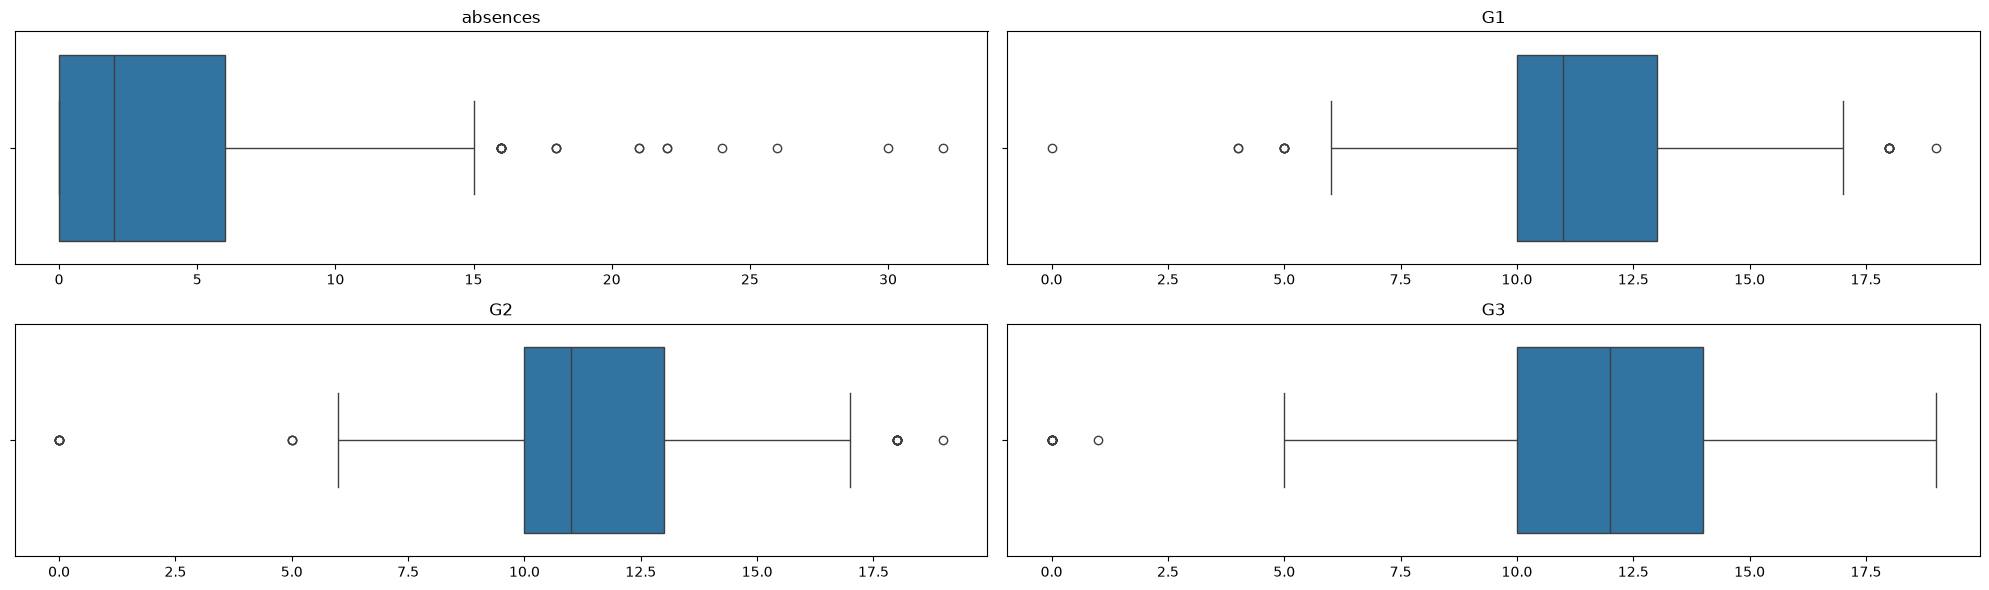

In [8]:
ds.box_plot_numeric(
	df_por,
	features=['absences', 'G1', 'G2', 'G3'],
	ncols=2
)
print('Numeric features boxplots')
plt.show()

The box plots above show outliers in all four numeric columns. Let's investigate them more closely.

In [9]:
df_por[df_por['G3'] == 0]

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
163,GP,M,18,U,LE3,T,1,1,other,other,course,mother,1,1,2,no,no,no,no,yes,no,yes,yes,2,3,5,2,5,4,0,11,9,0
440,MS,M,16,U,GT3,T,1,1,at_home,services,home,mother,2,2,0,no,yes,no,yes,yes,yes,no,yes,5,4,5,4,5,3,0,7,0,0
519,MS,M,16,R,GT3,T,2,1,other,services,reputation,mother,2,2,0,no,no,no,yes,yes,yes,yes,no,5,2,1,1,1,2,0,8,7,0
563,MS,M,17,U,GT3,T,2,2,other,other,course,mother,1,1,1,no,no,no,yes,yes,yes,no,yes,1,2,1,2,3,5,0,7,0,0
567,MS,M,18,R,GT3,T,3,2,services,other,course,mother,1,1,1,no,no,no,no,yes,no,yes,no,2,3,1,2,2,5,0,4,0,0
583,MS,F,18,R,GT3,T,2,2,other,other,other,mother,2,1,1,no,no,no,no,yes,no,yes,yes,5,5,5,1,1,3,0,8,6,0
586,MS,F,17,U,GT3,T,4,2,teacher,services,home,mother,1,2,0,yes,yes,no,yes,yes,yes,yes,no,5,5,5,1,3,5,0,8,8,0
597,MS,F,18,R,GT3,T,2,2,at_home,other,course,mother,3,2,1,no,no,no,yes,yes,yes,no,yes,4,3,3,1,1,4,0,9,0,0
603,MS,F,18,R,LE3,A,4,2,teacher,other,reputation,mother,1,2,0,no,no,no,yes,yes,yes,yes,yes,5,3,1,1,1,5,0,5,0,0
605,MS,F,19,U,GT3,T,1,1,at_home,services,other,father,2,1,1,no,no,no,no,yes,no,no,no,5,5,5,2,3,2,0,5,0,0


Most students with `G3` equal to $0$ are from Mousinho da Silveira, and all of them have $0$ absences. A zero final grade combined with zero absences most likely means that the student dropped out or did not take the final evaluation, not that they actually scored zero.

In [10]:
print(f'Number of students with a zero final grade: {(df_por["G3"] == 0).sum()}')
print(f'Percentage of students with a zero final grade: {(df_por["G3"] == 0).sum() / df_por.shape[0] * 100:.3f}%')

Number of students with a zero final grade: 15
Percentage of students with a zero final grade: 2.311%


In [11]:
# Students without a final grade by school
no_show = pd.DataFrame({
	'students with G3 = 0': df_por[df_por['G3'] == 0]['school'].value_counts(),
	'share of the school (%)': ((df_por['G3'] == 0).groupby(df_por['school']).mean() * 100).round(1),
})
no_show

,students with G3 = 0,share of the school (%)
school,,
GP,1,0.2
MS,14,6.2


These students make up less than $2.5\%$ of the dataset, so we drop them. However, the table above shows that this is more than a cleaning detail: 14 of the 15 students without a final grade are from Mousinho da Silveira, which is $6.2\%$ of that school's students, compared with $0.2\%$ (one student) at Gabriel Pereira. Dropping them therefore makes Mousinho da Silveira look somewhat better than it is, which we keep in mind for the [Schools Comparison](#schools-comparison).

In [12]:
df_por[df_por['G1'] == 0]

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,4,0,11,11


There is only one student with `G1 = 0`, and this student's final grade is 11, so this is most likely a missing first-period grade. We drop this student as well, so that the record does not distort the models that use `G1`.

In [13]:
df_por[df_por['G2'] == 0]

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
440,MS,M,16,U,GT3,T,1,1,at_home,services,home,mother,2,2,0,no,yes,no,yes,yes,yes,no,yes,5,4,5,4,5,3,0,7,0,0
563,MS,M,17,U,GT3,T,2,2,other,other,course,mother,1,1,1,no,no,no,yes,yes,yes,no,yes,1,2,1,2,3,5,0,7,0,0
567,MS,M,18,R,GT3,T,3,2,services,other,course,mother,1,1,1,no,no,no,no,yes,no,yes,no,2,3,1,2,2,5,0,4,0,0
597,MS,F,18,R,GT3,T,2,2,at_home,other,course,mother,3,2,1,no,no,no,yes,yes,yes,no,yes,4,3,3,1,1,4,0,9,0,0
603,MS,F,18,R,LE3,A,4,2,teacher,other,reputation,mother,1,2,0,no,no,no,yes,yes,yes,yes,yes,5,3,1,1,1,5,0,5,0,0
605,MS,F,19,U,GT3,T,1,1,at_home,services,other,father,2,1,1,no,no,no,no,yes,no,no,no,5,5,5,2,3,2,0,5,0,0
610,MS,F,19,R,GT3,A,1,1,at_home,at_home,course,other,2,2,3,no,yes,no,yes,yes,no,no,yes,3,5,4,1,4,1,0,8,0,0


All students with `G2 = 0` also have `G3 = 0`, so they are already being dropped.

In [14]:
df_por[ds.get_outliers_rows(df_por, cols='absences')].sort_values(by='absences')

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
40,GP,F,16,U,LE3,T,2,2,other,other,home,mother,2,2,0,no,yes,no,yes,no,yes,yes,yes,3,3,3,1,2,3,16,11,11,10
103,GP,F,15,U,GT3,T,3,2,services,other,home,mother,2,2,0,yes,yes,no,no,yes,yes,yes,no,4,3,5,1,1,2,16,11,10,10
206,GP,M,17,U,GT3,T,1,2,at_home,services,other,other,2,2,0,no,no,no,yes,no,yes,yes,no,4,4,4,4,5,5,16,10,11,12
161,GP,M,16,U,GT3,T,4,4,teacher,teacher,course,mother,1,1,0,no,yes,no,no,yes,no,yes,yes,3,3,2,2,1,5,16,9,9,8
211,GP,M,16,R,LE3,T,3,3,teacher,other,home,father,3,1,0,no,yes,no,yes,yes,yes,yes,no,3,3,4,3,5,3,16,10,11,12
263,GP,M,18,U,GT3,T,2,2,other,services,reputation,father,1,2,0,no,no,no,no,yes,no,yes,no,5,5,4,3,5,2,16,8,7,8
311,GP,F,19,U,GT3,T,3,3,other,services,home,other,1,2,0,no,yes,no,yes,yes,yes,yes,no,4,3,5,3,3,5,16,11,12,12
230,GP,F,17,U,GT3,T,4,3,other,other,reputation,mother,1,2,0,no,no,no,no,yes,yes,yes,yes,3,4,5,2,4,1,16,11,9,10
254,GP,F,18,U,LE3,T,2,2,at_home,services,course,mother,1,2,1,no,yes,no,no,no,yes,yes,yes,5,3,1,1,1,5,16,9,8,10
405,GP,F,19,U,LE3,A,2,3,at_home,other,home,other,2,1,1,no,no,no,no,yes,no,yes,no,2,2,3,3,4,5,16,10,11,11


All students with many absences are from Gabriel Pereira. Some of them underperform, but this group does not seem to need a deeper investigation, so we keep them as they are.

In [15]:
# dropping students with G3=0 and G1=0
df_por = df_por[(df_por['G3'] != 0) & (df_por['G1'] != 0)]

# 3. Data Exploration (Continue EDA)

We start exploring how strongly different factors are associated with academic performance with an overview: a ranking of how much of the variance of the final grade (`G3`) each feature explains. For categorical features and numeric features with low cardinality ($\le5$ distinct values), the explained variance is measured with $\eta^2$ (eta squared); for numeric features with higher cardinality ($>5$), with $R^2$ (R squared).

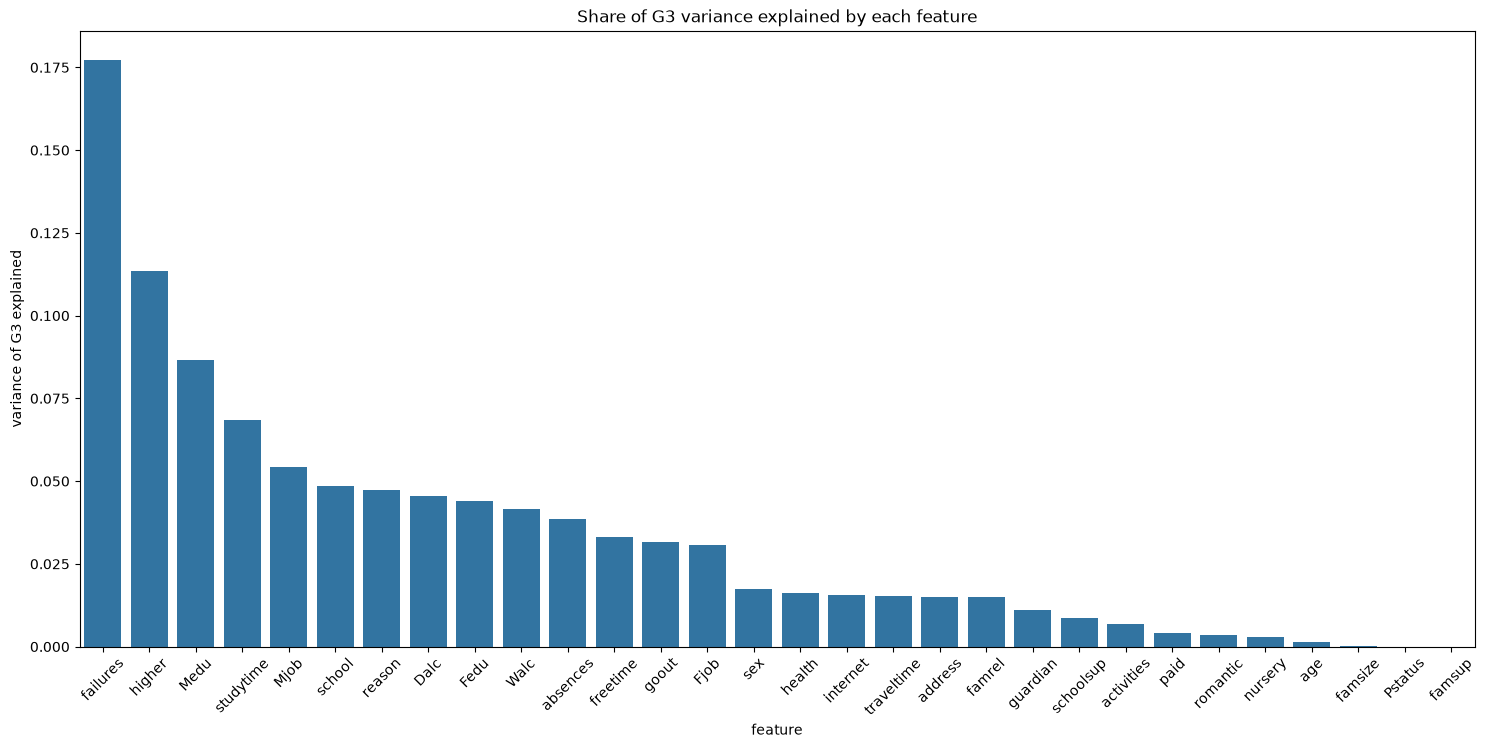

In [16]:
var_ranking = ds.variance_ranking(df_por, 'G3')

# We exclude 'G1' and 'G2' features from the plot to make it more readable
df_variance = pd.DataFrame(data=var_ranking[2:], columns=['feature', 'variance of G3 explained'])

plt.figure(figsize=(18, 8))
ax = sns.barplot(
	data=df_variance,
	x='feature',
	y='variance of G3 explained'
)

plt.xticks(rotation=45)
ax.set_title('Share of G3 variance explained by each feature')
plt.show()

Based on the Portuguese grading system, we group the final grades into 3 categories:
|Grade range|Meaning|
|-----------|-------|
|0–9|Fail (insufficient)|
|10–15|Sufficient / Good|
|16–20|Very Good / Excellent|

In [17]:
df_por['Grade Category'] = ds.categorize_numeric(
	df_por['G3'],
	binning=[0, 10, 16, 21],
	labels=['Fail (<10)', 'Sufficient / Good (10-15)', 'Very Good / Excellent (16-20)']
)
df_por.sample(5, random_state=42)

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,Grade Category
331,GP,M,17,U,GT3,T,1,1,other,other,reputation,father,1,2,0,no,no,no,no,no,yes,yes,no,4,3,3,1,2,4,0,12,12,12,Sufficient / Good (10-15)
249,GP,M,16,U,GT3,T,3,2,at_home,other,reputation,mother,2,3,0,no,no,no,yes,yes,yes,yes,yes,5,3,3,1,3,2,0,12,12,12,Sufficient / Good (10-15)
392,GP,F,17,U,GT3,T,3,2,other,other,home,mother,1,2,0,no,yes,no,no,yes,yes,yes,yes,4,3,2,2,3,2,0,12,13,15,Sufficient / Good (10-15)
146,GP,M,16,U,LE3,T,1,1,services,other,course,mother,1,2,2,no,no,no,no,yes,yes,no,yes,4,4,4,1,3,5,0,10,10,10,Sufficient / Good (10-15)
500,MS,M,17,U,GT3,T,1,2,other,other,course,father,1,1,1,no,yes,no,yes,yes,no,yes,yes,5,3,5,5,5,1,12,6,7,7,Fail (<10)


## Family Factors

Let's begin with *family factors*: `Fedu`, `Medu`, `Fjob` and `Mjob`.

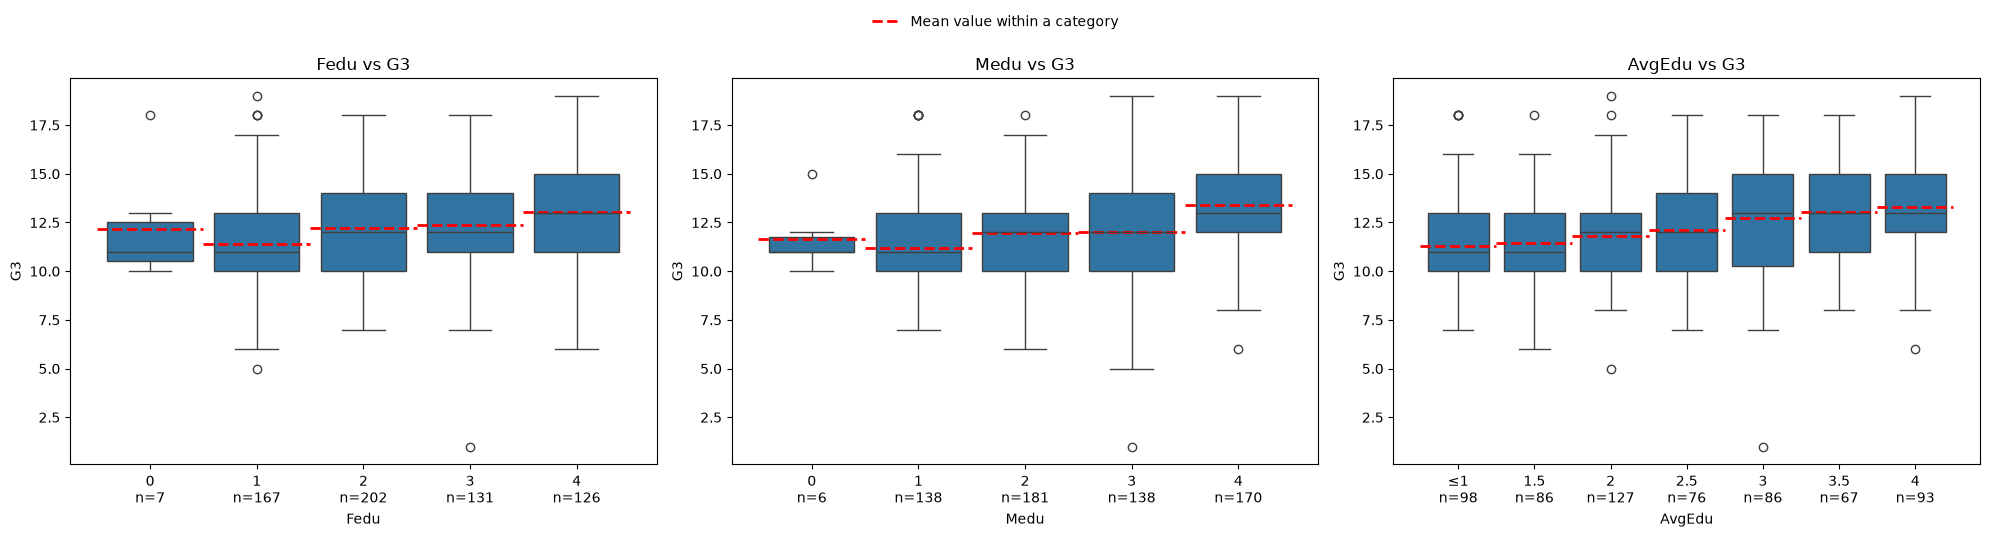

In [18]:
df_fam_por = df_por.copy()

# Additional feature: the parents' average education level (levels below 1 are merged, as they are tiny)  
avg_edu = ((df_fam_por['Fedu'] + df_fam_por['Medu']) / 2).clip(lower=1)

df_fam_por['AvgEdu'] = pd.Categorical(
	avg_edu,
	categories=[1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0],
	ordered=True
).rename_categories(['≤1', '1.5', '2', '2.5', '3', '3.5', '4'])

fam_edu_features = ['Fedu', 'Medu', 'AvgEdu']

ds.plot_target(
	df=df_fam_por, 
	target='G3', 
	features=fam_edu_features, 
	show_mean=True,
	display_count=True
)

plt.show()

Children of more educated parents tend to have better grades, whether we look at each parent separately or at the parents' average education level. (Average education levels below 1 are merged into one group, because they contain very few students.)

Next, we calculate Spearman's rank correlation coefficients and run Kruskal–Wallis H tests to put numbers on these observations and to check whether they are statistically significant.

In [19]:
ds.ordinal_association(
	df=df_fam_por,
	target='G3',
	features=['Fedu', 'Medu', 'AvgEdu']
)

,feature,spearman_rho,p_spearman,kruskal_H,p_kruskal,eta2
0,Medu,0.290,1.001844e-13,59.84,3.128628e-12,0.086
1,AvgEdu,0.281,5.774103e-13,51.29,2.593438e-09,0.071
2,Fedu,0.222,1.706122e-08,32.42,1.572923e-06,0.044


All p-values in the table above are far below the usual significance level $\alpha=0.05$, so these associations are statistically significant. The positive Spearman's $\rho$ values show that all three features are positively associated with grades. `Medu` is the most strongly associated feature, with the highest $\rho$, $H$ and $\eta^2$, although its $\eta^2=0.086$ means that it still explains less than $9\%$ of the variance of the final grade.

Next, let's look at how parents' jobs relate to students' grades.

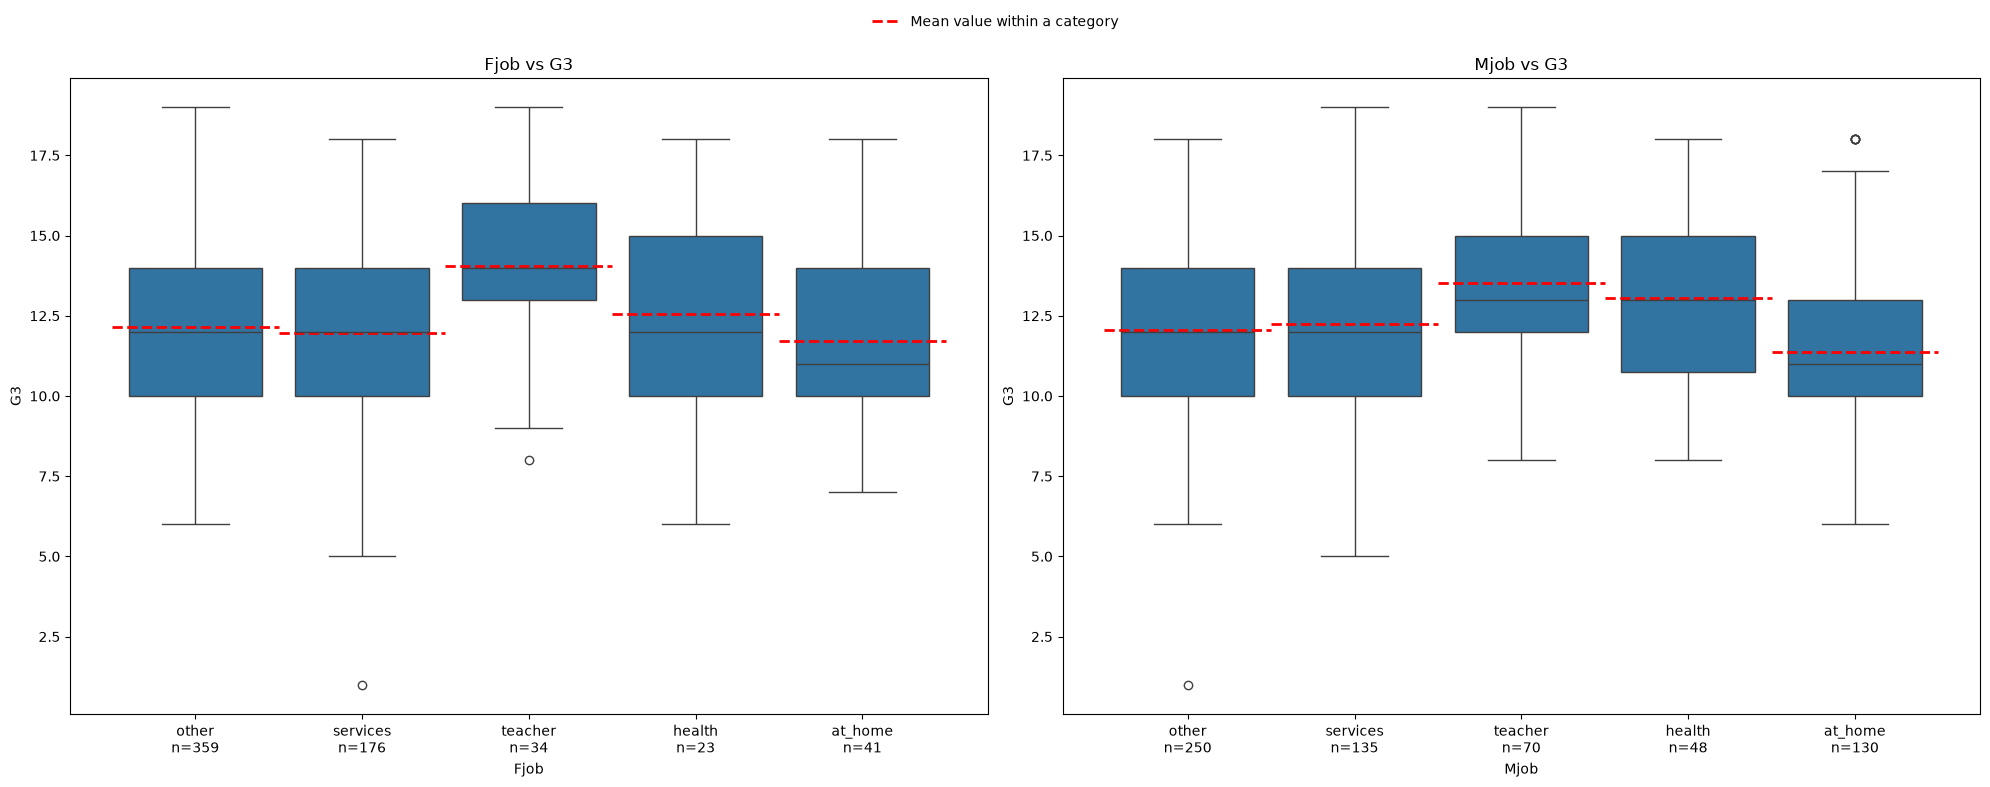

In [20]:
job_features = ['Fjob', 'Mjob']
fig, axes = ds.plot_target(
	df=df_por,
	target='G3',
	show_mean=True,
	features=job_features,
	display_count=True,
	order=df_por['Fjob'].unique()
)

plt.show()

The children with the best results are those whose mothers work in health care or as teachers, and those whose fathers are teachers. However, mothers who work as teachers or health workers may simply have a higher level of education, and education, rather than the job itself, might be what is related to their children's higher grades. Let's investigate this.

In [21]:
pd.crosstab(
	index=df_por['Mjob'],
	columns=df_por['Medu'],
	normalize='index'
)

Medu,0,1,2,3,4
Mjob,,,,,
at_home,0.023077,0.492308,0.300000,0.153846,0.030769
health,0.000000,0.041667,0.104167,0.104167,0.750000
other,0.012000,0.264000,0.364000,0.232000,0.128000
services,0.000000,0.044444,0.340741,0.385185,0.229630
teacher,0.000000,0.000000,0.000000,0.042857,0.957143


In [22]:
pd.crosstab(
	index=df_por['Fjob'],
	columns=df_por['Fedu'],
	normalize='index'
)

Fedu,0,1,2,3,4
Fjob,,,,,
at_home,0.024390,0.365854,0.390244,0.146341,0.073171
health,0.000000,0.000000,0.130435,0.130435,0.739130
other,0.016713,0.309192,0.348189,0.203343,0.122563
services,0.000000,0.227273,0.329545,0.272727,0.170455
teacher,0.000000,0.029412,0.000000,0.029412,0.941176


The tables above confirm this. $95.7\%$ of mothers who work as teachers have the highest education level ($4$), and the remaining $4.3\%$ have level $3$. The picture for mothers who work in health care is similar: $75\%$ have level $4$ and $10.4\%$ level $3$. Among fathers, $94.1\%$ of teachers and $73.9\%$ of health workers have the highest education level.

To separate the job from the education level, let's compare grades by job *within the same education level*.

In [23]:
# Mean final grade by parent's job within each education level, followed by the group sizes
display(df_por.pivot_table(index='Medu', columns='Mjob', values='G3', aggfunc='mean').round(2))
display(df_por.pivot_table(index='Medu', columns='Mjob', values='G3', aggfunc='count'))
display(df_por.pivot_table(index='Fedu', columns='Fjob', values='G3', aggfunc='mean').round(2))
display(df_por.pivot_table(index='Fedu', columns='Fjob', values='G3', aggfunc='count'))

Mjob,at_home,health,other,services,teacher
Medu,,,,,
0,12.33,NaN,11.00,NaN,NaN
1,11.36,10.00,10.95,12.33,NaN
2,11.59,10.40,12.12,12.22,NaN
3,10.90,13.60,12.40,11.75,13.67
4,11.50,13.53,13.53,13.06,13.51


Mjob,at_home,health,other,services,teacher
Medu,,,,,
0,3.0,NaN,3.0,NaN,NaN
1,64.0,2.0,66.0,6.0,NaN
2,39.0,5.0,91.0,46.0,NaN
3,20.0,5.0,58.0,52.0,3.0
4,4.0,36.0,32.0,31.0,67.0


Fjob,at_home,health,other,services,teacher
Fedu,,,,,
0,13.00,NaN,12.00,NaN,NaN
1,10.73,NaN,11.45,11.42,14.00
2,12.19,13.00,12.49,11.52,NaN
3,11.83,11.00,12.40,12.48,14.00
4,13.33,12.76,12.61,12.70,14.06


Fjob,at_home,health,other,services,teacher
Fedu,,,,,
0,1.0,NaN,6.0,NaN,NaN
1,15.0,NaN,111.0,40.0,1.0
2,16.0,3.0,125.0,58.0,NaN
3,6.0,3.0,73.0,48.0,1.0
4,3.0,17.0,44.0,30.0,32.0


In [24]:
# Highest education level only: do parents' jobs still matter?
medu_4 = df_por[(df_por['Medu'] == 4) & (df_por['Mjob'] != 'at_home')]  # only 4 at_home mothers have Medu = 4
mjob_groups, _ = ds.get_groups(df=medu_4, by='Mjob', columns='G3')
print(f'Mothers with Medu = 4, Kruskal-Wallis p-value: {kruskal(*mjob_groups).pvalue:.3f}')

fedu_4 = df_por[df_por['Fedu'] == 4]
father_teacher = fedu_4.loc[fedu_4['Fjob'] == 'teacher', 'G3']
father_other = fedu_4.loc[fedu_4['Fjob'] != 'teacher', 'G3']
print(f'Fathers with Fedu = 4: teacher mean = {father_teacher.mean():.2f} (n = {len(father_teacher)}), other jobs mean = {father_other.mean():.2f} (n = {len(father_other)})')
print(f'Mann-Whitney p-value: {mannwhitneyu(father_teacher, father_other).pvalue:.3f}')

Mothers with Medu = 4, Kruskal-Wallis p-value: 0.854
Fathers with Fedu = 4: teacher mean = 14.06 (n = 32), other jobs mean = 12.69 (n = 94)
Mann-Whitney p-value: 0.015


Within the same education level, most of the differences between mothers' jobs disappear. Among mothers with the highest education level (`Medu = 4`), the mean final grade is about $13.5$ for teachers, health workers and the "other" group alike, and $13.1$ for services; a Kruskal–Wallis test finds no difference ($\text{p-value}\approx0.85$). The mother's job is therefore mostly a proxy for her education.

Fathers are different. Among fathers with the highest education level (`Fedu = 4`), children of teachers still score $14.1$ on average, compared with $12.7$ for children of fathers with other jobs ($\text{p-value}\approx0.015$). This group is small ($n=32$), so the result should be treated with caution, but it suggests that having a father who is a teacher is associated with higher grades beyond what his education level explains.

## Educational Factors

Next, we explore how "educational factors" (`studytime`, `failures`, `schoolsup`, `paid`, `internet` and `higher`) are related to students' performance.

Let's begin with the binary features: `schoolsup`, `paid`, `internet` and `higher`.

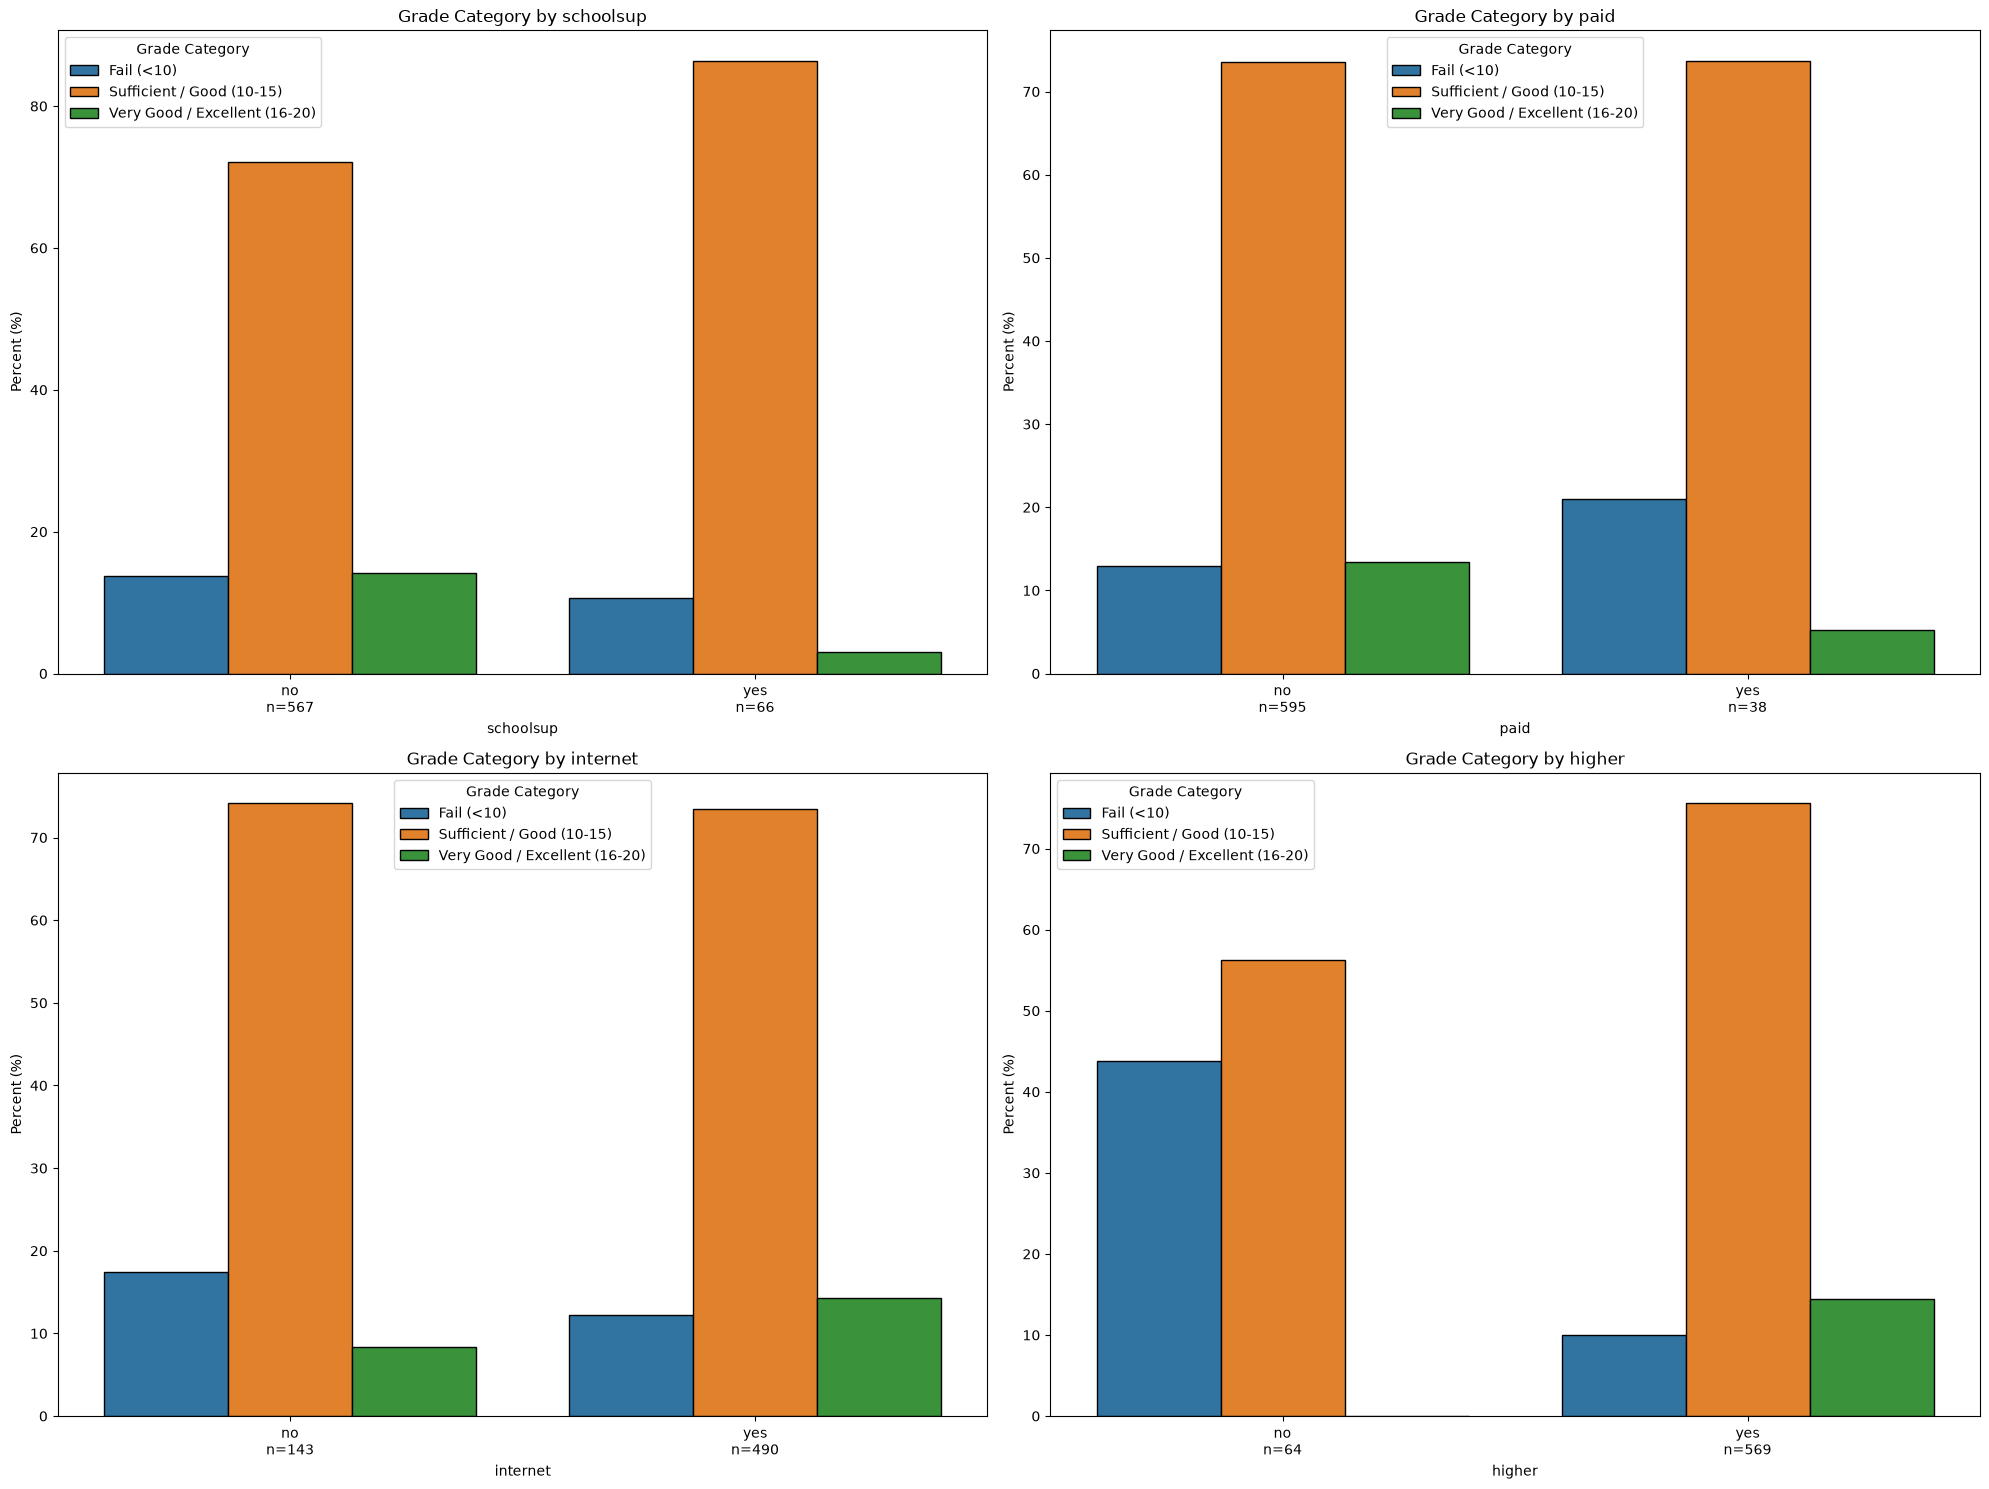

In [25]:
edu_binary_features = [
	'schoolsup',
	'paid',
	'internet',
	'higher'
]

df_edu_por = df_por.copy()

ds.distr_comp(
	df=df_por,
	features=edu_binary_features,
	target='Grade Category',
	display_count=True,
	ncols=2
)

plt.show()

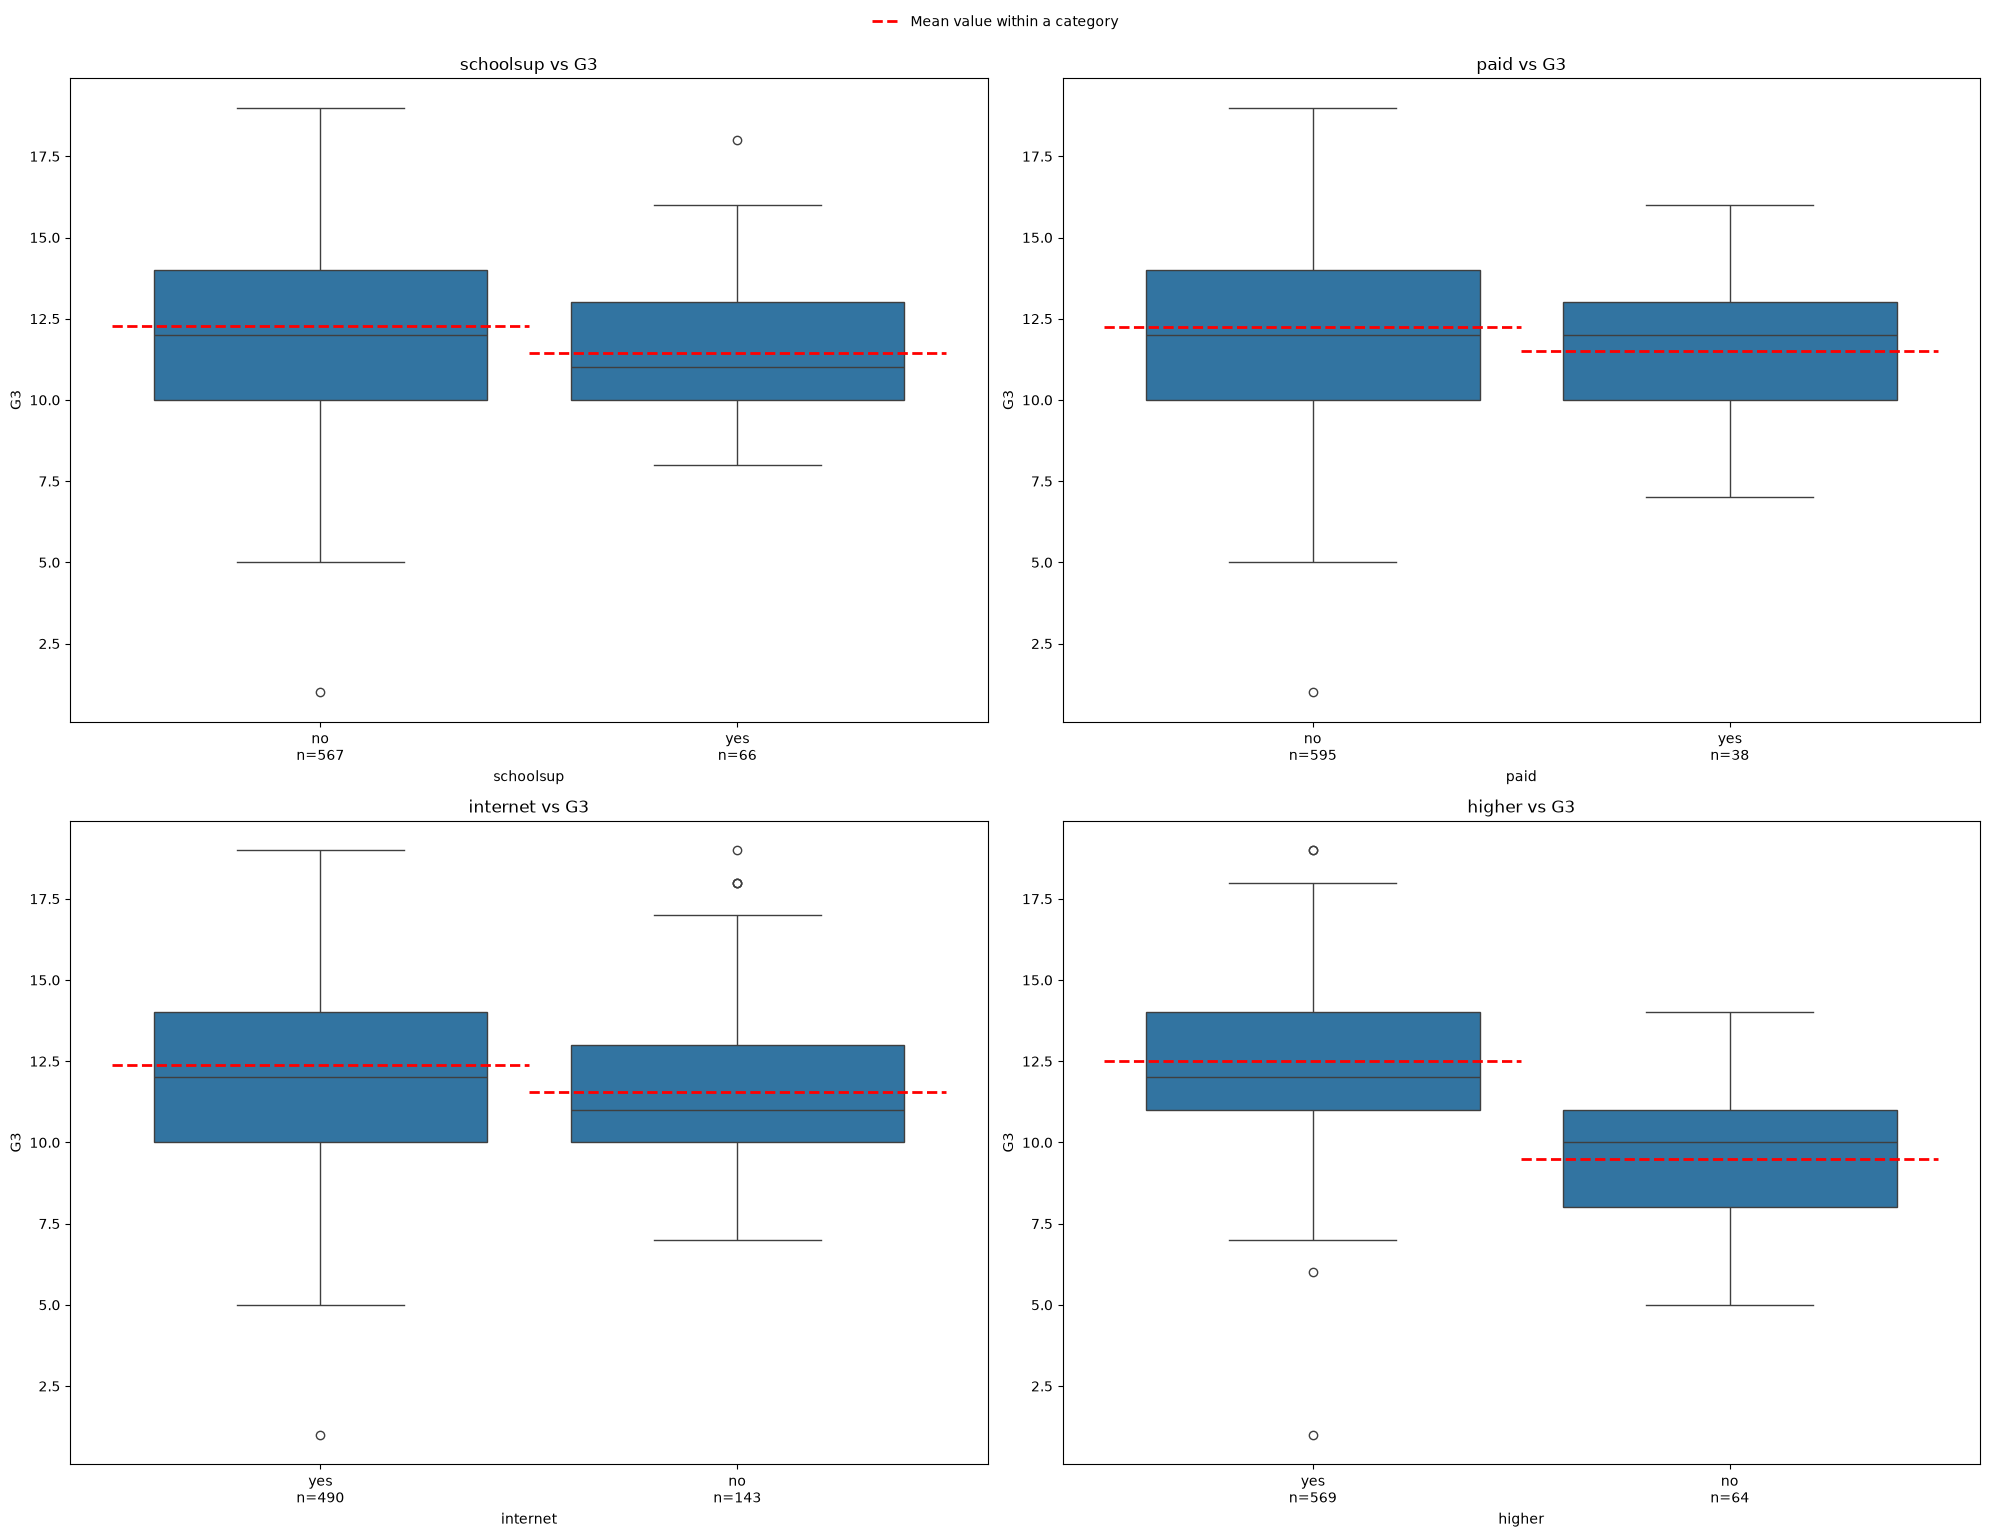

In [26]:
fig, axes = ds.plot_target(
	df=df_por,
	target='G3',
	show_mean=True,
	features=edu_binary_features,
	ncols=2,
	display_count=True
)
plt.show()

In [27]:
eta_sq_bin = [
	[i, ds.eta_squared(df_por[i], df_por['G3'])] 
	for i in edu_binary_features
]
df_eta_bin = pd.DataFrame(
	data=eta_sq_bin,
	columns=['Feature', 'eta-squared']
)
df_eta_bin

,Feature,eta-squared
0,schoolsup,0.008682
1,paid,0.004192
2,internet,0.015644
3,higher,0.113634


In [28]:
# School support and paid classes: group sizes, mean grades and Mann-Whitney U tests
support_rows = []
for f in ['schoolsup', 'paid']:
	yes = df_por[df_por[f] == 'yes']
	no = df_por[df_por[f] == 'no']
	support_rows.append({
		'feature': f,
		'n (yes)': len(yes),
		'n (no)': len(no),
		'mean G3 (yes)': yes['G3'].mean(),
		'mean G3 (no)': no['G3'].mean(),
		'mean G1 (yes)': yes['G1'].mean(),
		'mean G1 (no)': no['G1'].mean(),
		'Mann-Whitney p-value (G3)': mannwhitneyu(yes['G3'], no['G3']).pvalue,
	})

pd.DataFrame(support_rows).round(3)

,feature,n (yes),n (no),mean G3 (yes),mean G3 (no),mean G1 (yes),mean G1 (no),Mann-Whitney p-value (G3)
0,schoolsup,66,567,11.455,12.275,11.030,11.577,0.017
1,paid,38,595,11.500,12.234,10.816,11.565,0.141


In [29]:
print("Shares of students who plan to pursue higher education")
display(df_por[df_por['higher'] == 'yes']['Grade Category'].value_counts(normalize=True))
print("Shares of students who do not plan to pursue higher education")
display(df_por[df_por['higher'] == 'no']['Grade Category'].value_counts(normalize=True))

Shares of students who plan to pursue higher education


Grade Category
Sufficient / Good (10-15)        0.755712
Very Good / Excellent (16-20)    0.144112
Fail (<10)                       0.100176
Name: proportion, dtype: float64

Shares of students who do not plan to pursue higher education


Grade Category
Sufficient / Good (10-15)        0.5625
Fail (<10)                       0.4375
Very Good / Excellent (16-20)    0.0000
Name: proportion, dtype: float64

In [30]:
print("Shares of students with internet access at home")
display(df_por[df_por['internet'] == 'yes']['Grade Category'].value_counts(normalize=True))
print("Shares of students without internet access at home")
display(df_por[df_por['internet'] == 'no']['Grade Category'].value_counts(normalize=True))

Shares of students with internet access at home


Grade Category
Sufficient / Good (10-15)        0.734694
Very Good / Excellent (16-20)    0.142857
Fail (<10)                       0.122449
Name: proportion, dtype: float64

Shares of students without internet access at home


Grade Category
Sufficient / Good (10-15)        0.741259
Fail (<10)                       0.174825
Very Good / Excellent (16-20)    0.083916
Name: proportion, dtype: float64

Several observations can be made from the plots and tables above:
1. Students who receive extra educational support from the school (`schoolsup`, $n=66$) or take paid extra classes (`paid`, $n=38$) have slightly lower grades than those who don't: the mean final grade is $11.45$ vs $12.28$ for school support ($\text{p-value}\approx0.017$) and $11.50$ vs $12.23$ for paid classes ($\text{p-value}\approx0.14$, not significant). These groups also include fewer "high graders" (16–20). The effects are very weak ($\eta^2=0.009$ and $0.004$). Most importantly, these students already had lower first-period grades (`G1`: $11.03$ vs $11.58$ and $10.82$ vs $11.56$), so support is most likely given *because* students struggle. This data therefore cannot show whether the support helps.
2. Students with internet access at home include a smaller share of failing students ($12.2\%$ vs $17.5\%$) and a larger share of "high graders" ($14.3\%$ vs $8.4\%$). However, internet access is probably a proxy for family background rather than a factor on its own; we check this below.
3. The intention to pursue higher education shows the strongest association of these four features ($\eta^2\approx0.114$). All "high graders" plan to pursue higher education, and only $10\%$ of the students with such plans fail, compared with $43.75\%$ of those without them.

In [31]:
# Is internet access a proxy for family background?
display(pd.crosstab(df_por['address'], df_por['internet'], normalize='index').round(3))
display(pd.crosstab(df_por['Medu'], df_por['internet'], normalize='index').round(3))
df_por.pivot_table(index='address', columns='internet', values='G3', aggfunc=['mean', 'count']).round(2)

internet,no,yes
address,,
R,0.342,0.658
U,0.177,0.823


internet,no,yes
Medu,,
0,0.500,0.500
1,0.399,0.601
2,0.238,0.762
3,0.203,0.797
4,0.082,0.918


mean        count     
internet     no    yes    no  yes
address                          
R         11.77  11.63    64  123
U         11.41  12.62    79  367

Internet access is closely tied to family background. $82\%$ of urban students have internet access at home, compared with $66\%$ of rural students, and the share grows with the mother's education level from $60\%$ (`Medu = 1`) to $92\%$ (`Medu = 4`). Among rural students, those with and without internet access have practically the same mean final grade ($11.6$ vs $11.8$); the gap appears only among urban students ($12.6$ vs $11.4$). The association between internet access and grades therefore most likely reflects differences in family background rather than an effect of internet access itself.

Now let's explore the numeric "educational factors": `studytime` and `failures`.

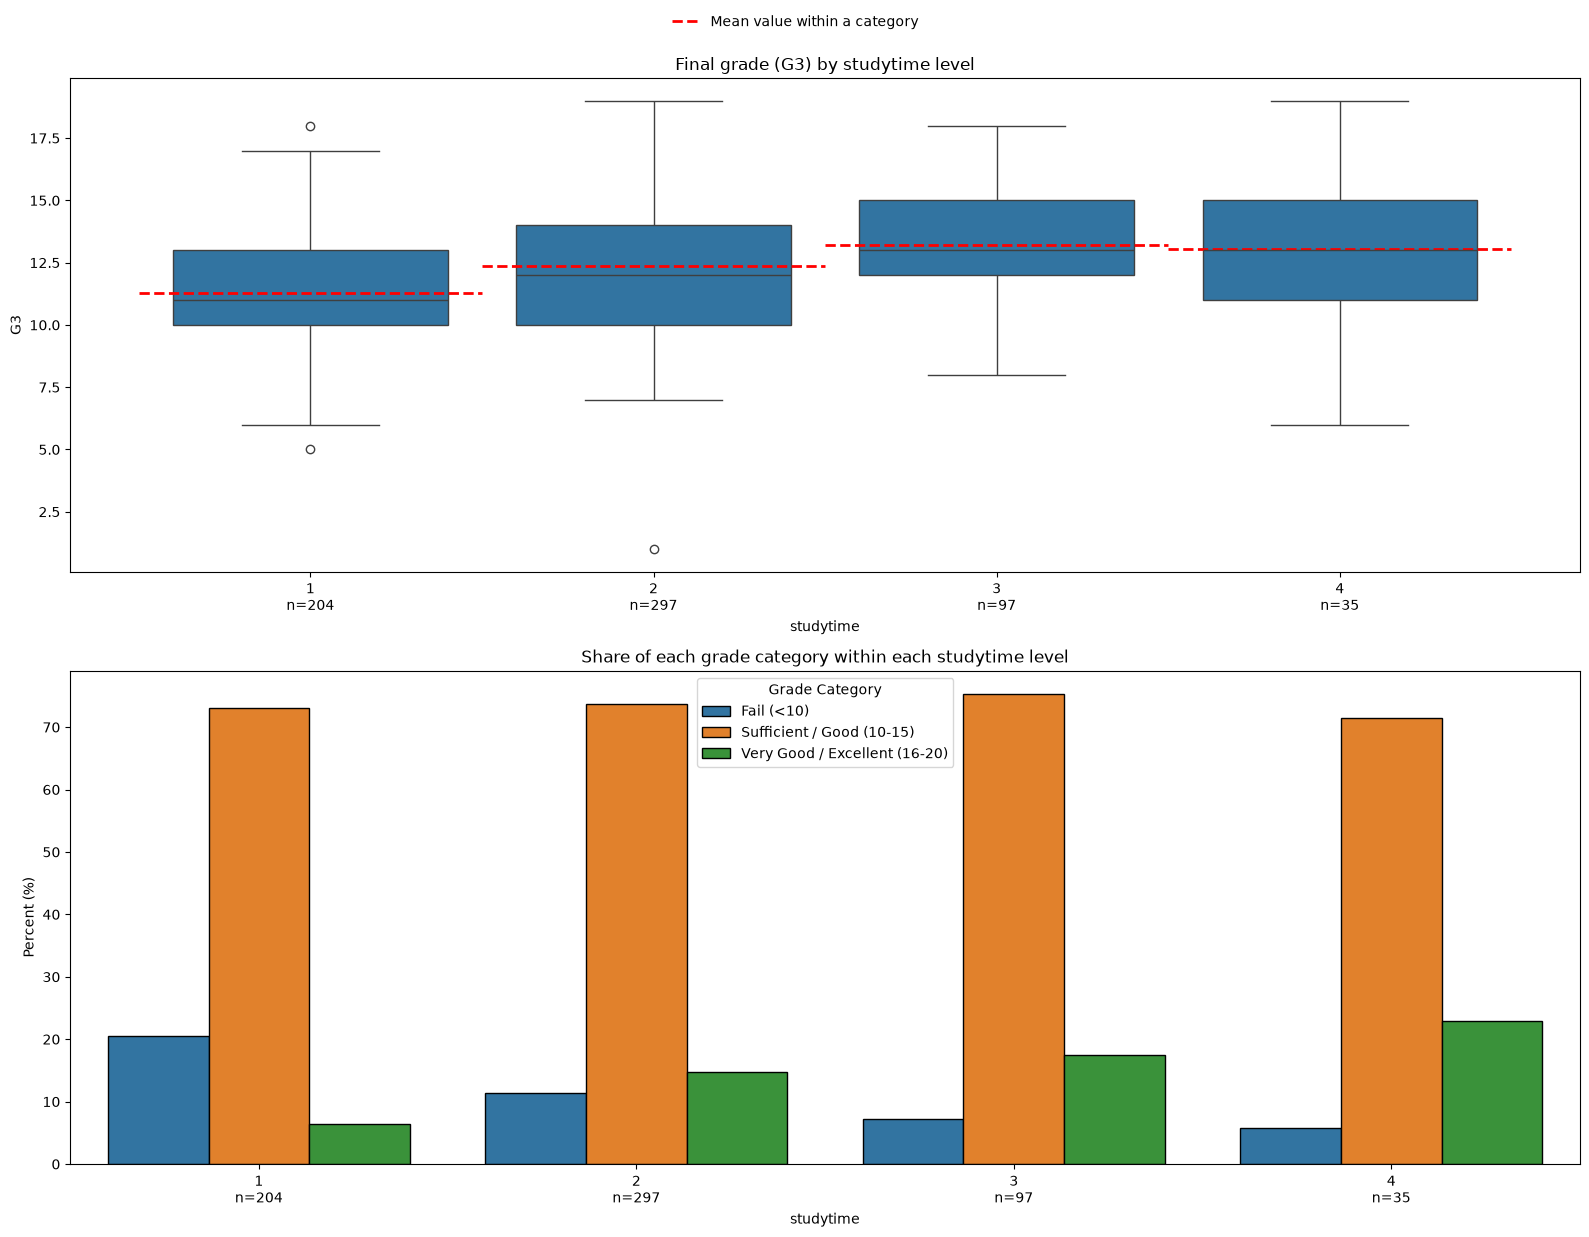

In [32]:
fig, (ax1, ax2) = plt.subplots(nrows=2, ncols=1)

ds.distr_comp(
	df=df_por,
	features='studytime',
	target='Grade Category',
	display_count=True,
	ax=ax2
)

ds.plot_target(
	df=df_por,
	features='studytime',
	target='G3',
	display_count=True,
	show_mean=True,
	ax=ax1
)

fig.set_size_inches(16, 12)
ax2.set_title("Share of each grade category within each studytime level")
ax1.set_title("Final grade (G3) by studytime level")
fig.tight_layout()
plt.show()

In [33]:
ds.ordinal_association(
	df=df_por,
	target='G3',
	features='studytime'
)

,feature,spearman_rho,p_spearman,kruskal_H,p_kruskal,eta2
0,studytime,0.264,1.535464e-11,45.59,6.936289e-10,0.069


1. Study time is positively correlated with grades: Spearman's $\rho=0.264$, $\text{p-value}\ll0.05$.
2. Performance improves steadily as study time increases:
	- the share of "high graders" goes up;
	- the share of failing students goes down.

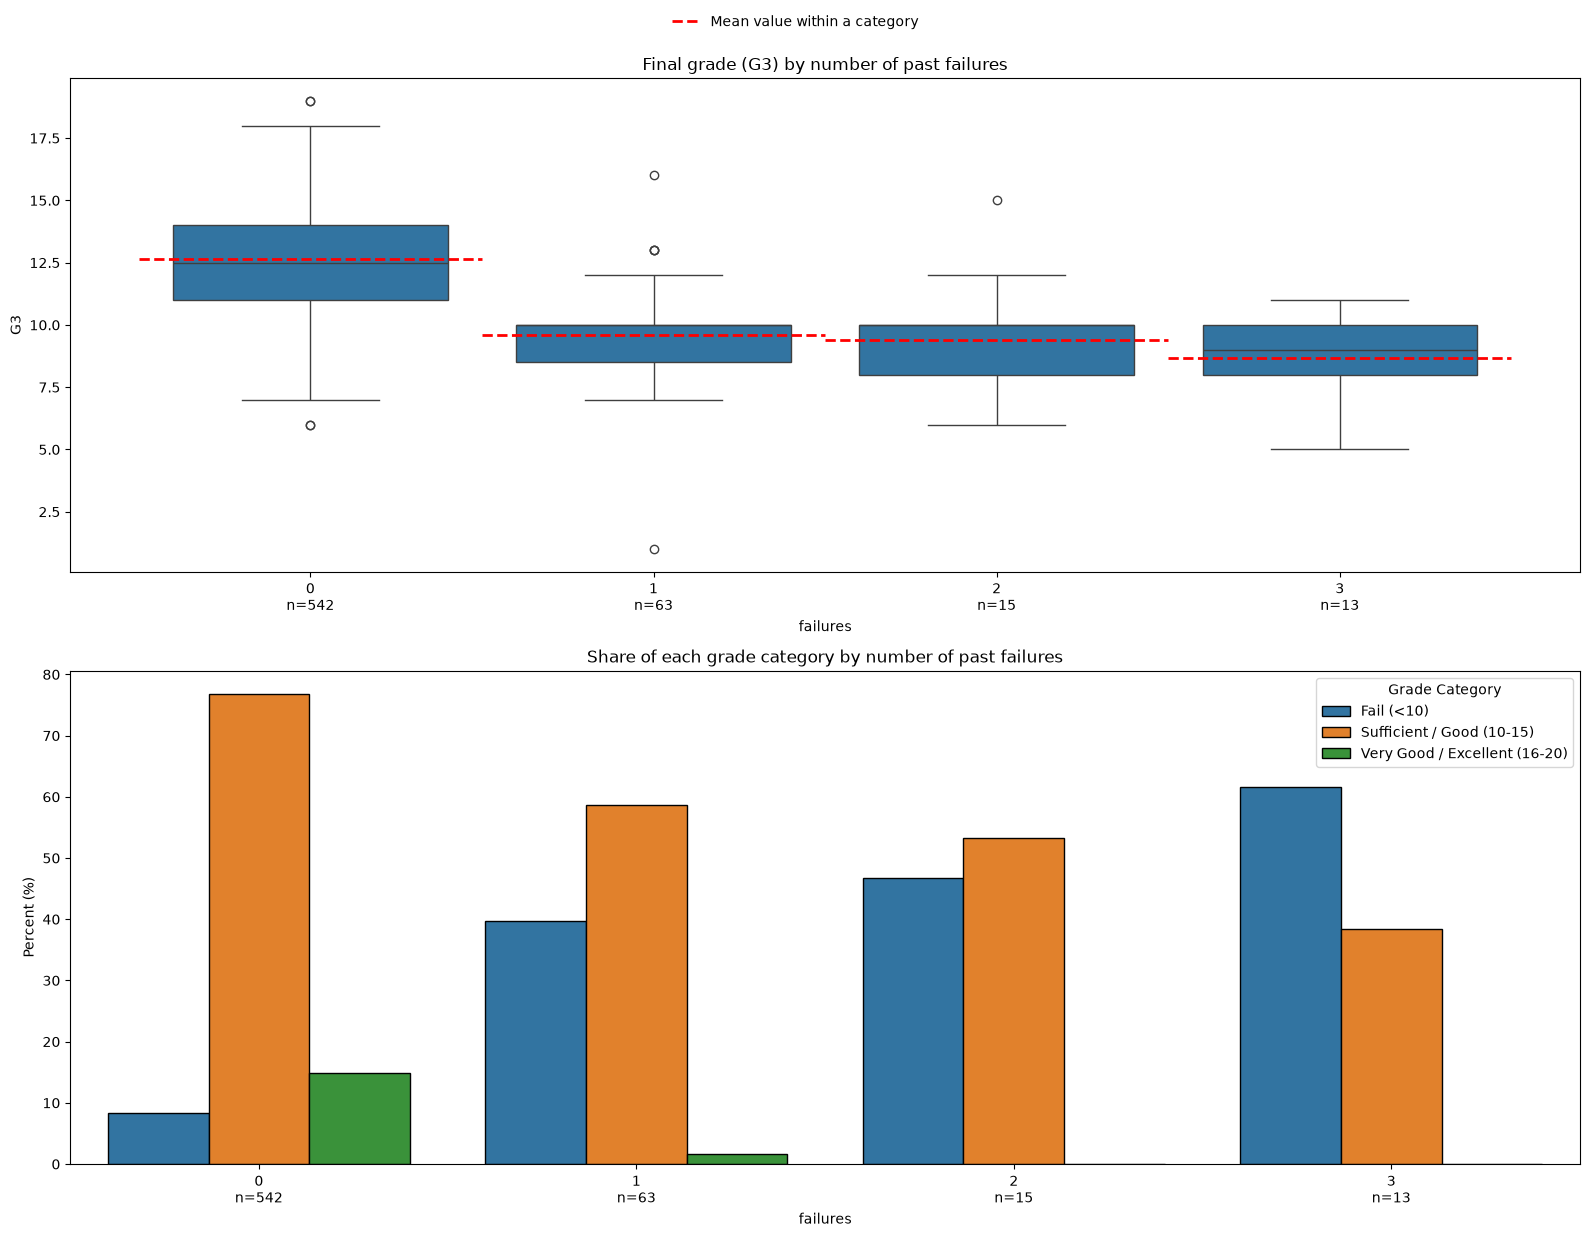

In [34]:
fig, (ax1, ax2) = plt.subplots(nrows=2, ncols=1)

ds.distr_comp(
	df=df_por,
	features='failures',
	target='Grade Category',
	display_count=True,
	ax=ax2
)

ds.plot_target(
	df=df_por,
	features='failures',
	target='G3',
	display_count=True,
	show_mean=True,
	ax=ax1
)

fig.set_size_inches(16, 12)
ax2.set_title("Share of each grade category by number of past failures")
ax1.set_title("Final grade (G3) by number of past failures")
fig.tight_layout()
plt.show()

In [35]:
ds.ordinal_association(
	df=df_por,
	target='G3',
	features='failures'
)

,feature,spearman_rho,p_spearman,kruskal_H,p_kruskal,eta2
0,failures,-0.431,4.989947e-30,117.76,2.342135e-25,0.177


In [36]:
failures_summary_df = pd.crosstab(
	index=df_por['failures'],
	columns=df_por['Grade Category'],
	margins=True
)
failures_summary_df

Grade Category,Fail (<10),Sufficient / Good (10-15),Very Good / Excellent (16-20),All
failures,,,,
0,45,416,81,542
1,25,37,1,63
2,7,8,0,15
3,8,5,0,13
All,85,466,82,633


1. Most students ($542$ out of $633$, i.e. more than $85\%$) have no past failures.
2. `failures` is negatively correlated with grades: Spearman's $\rho=-0.431$, $\text{p-value}\ll0.05$.
3. $\eta^2=0.177$ means that past failures explain about $18\%$ of the variance of the final grade.
4. All "high graders" except one have no past failures.

## Social Factors

Finally, we explore how social factors (`freetime`, `goout`, `Dalc` and `Walc`) relate to academic performance.

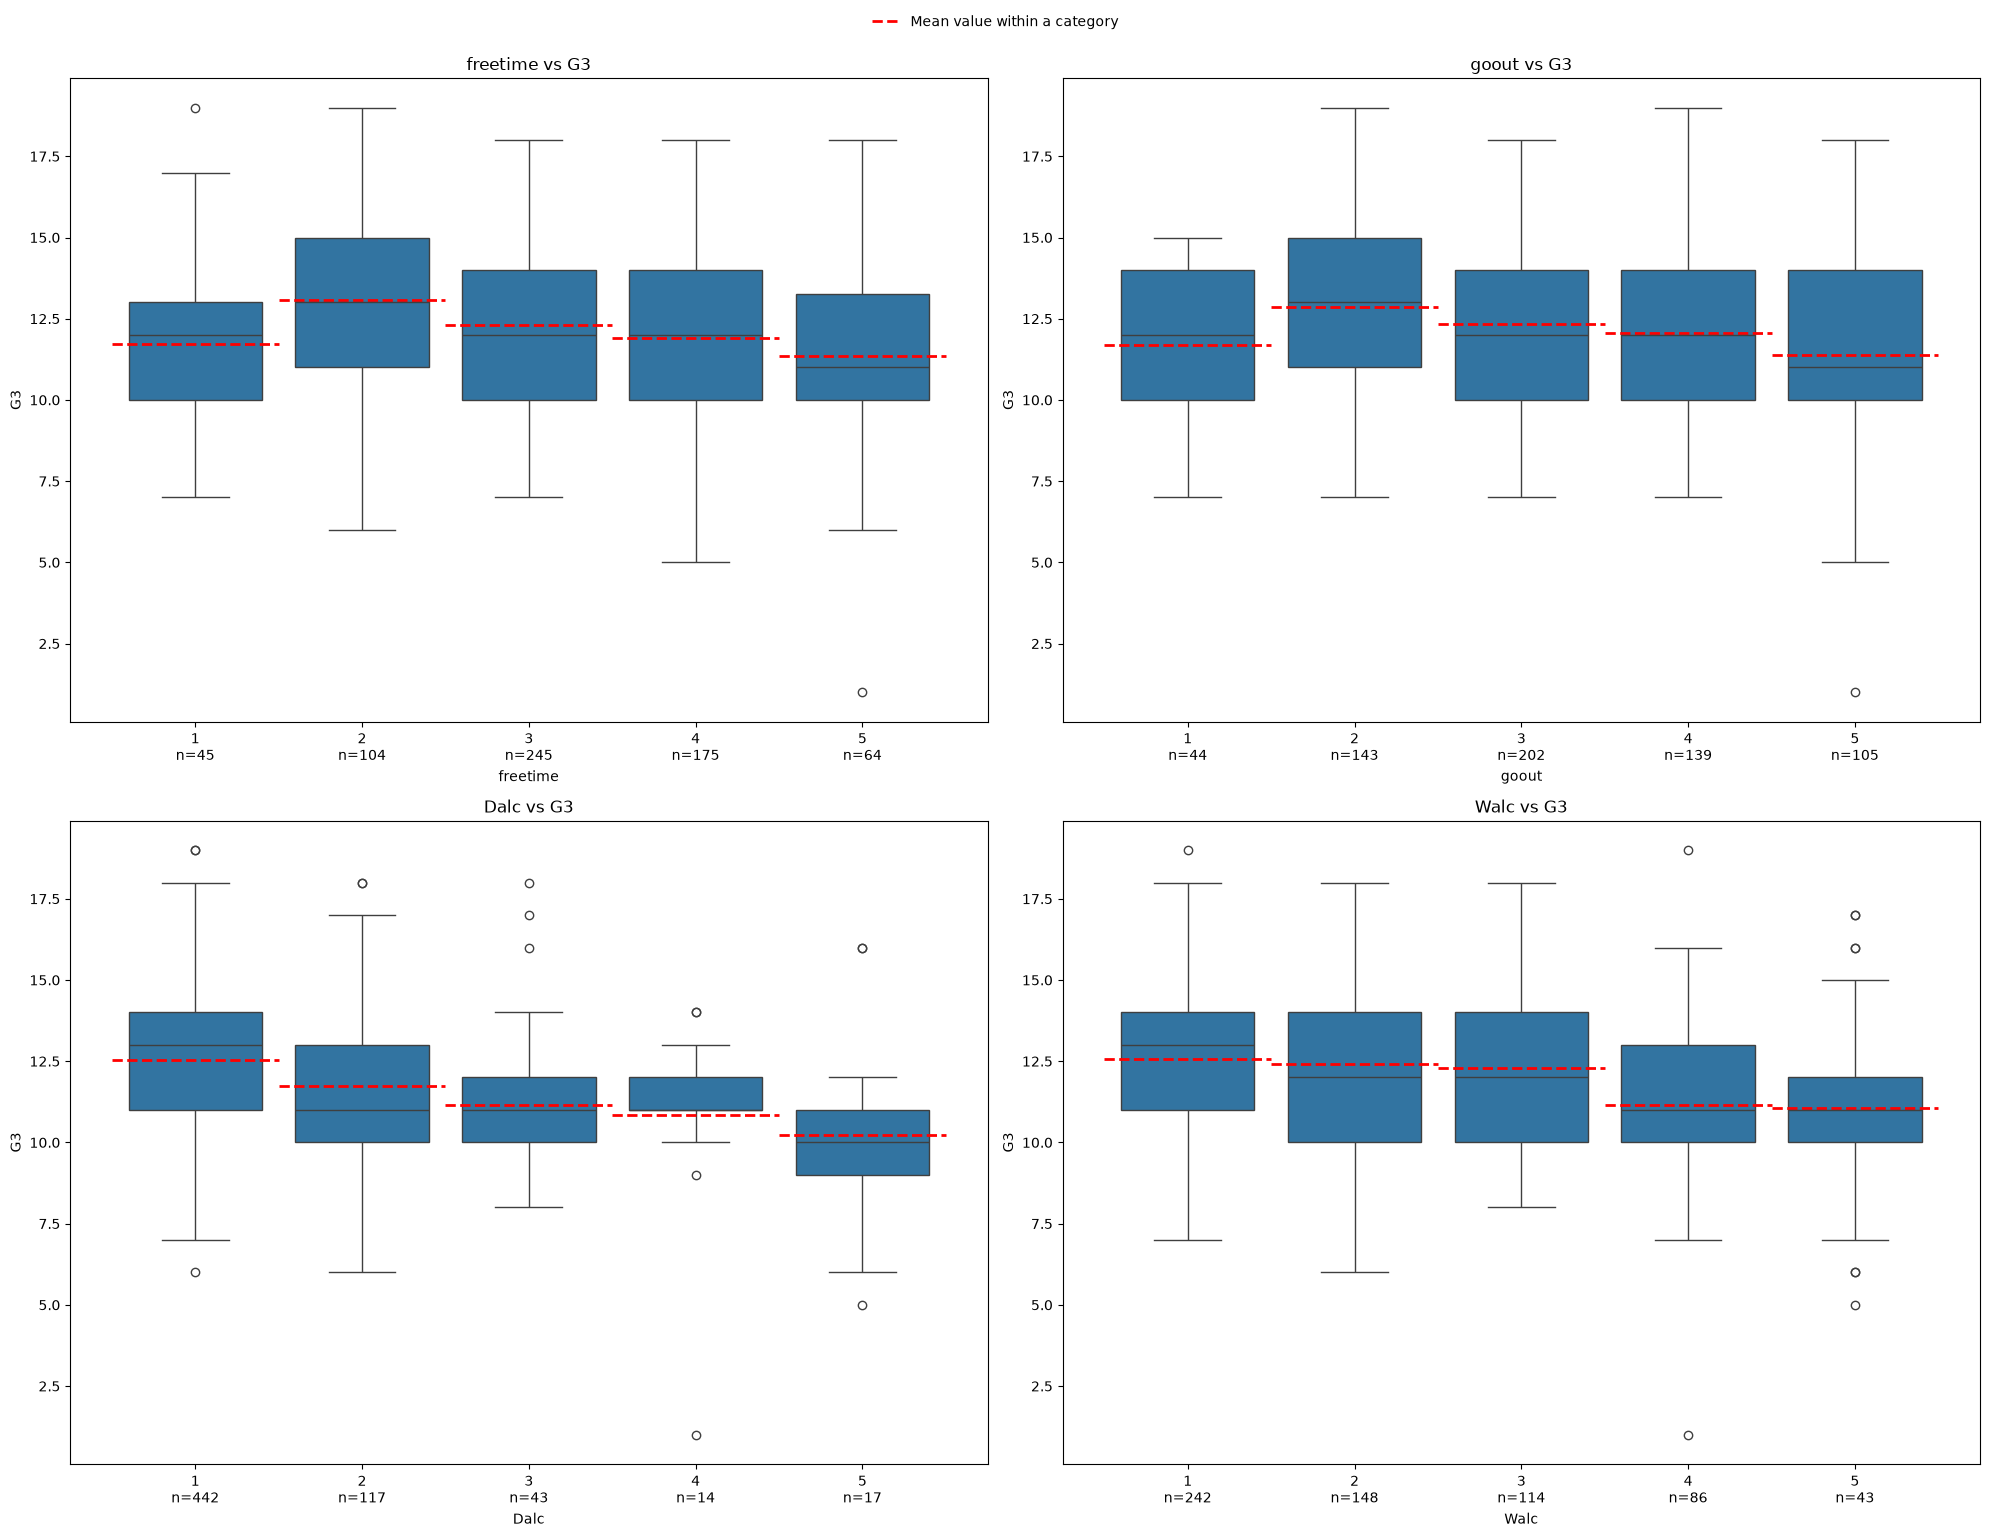

In [37]:
df_soc_por = df_por.copy()

soc_features = [
	'freetime',
	'goout',
	'Dalc',
	'Walc'
]

ds.plot_target(
	df=df_por,
	features=soc_features,
	target='G3',
	display_count=True,
	show_mean=True,
	ncols=2
)
plt.show()


In [38]:
ds.ordinal_association(
	df=df_por,
	target='G3',
	features=soc_features
)

,feature,spearman_rho,p_spearman,kruskal_H,p_kruskal,eta2
0,Dalc,-0.204,2.221058e-07,28.72,0.000009,0.046
1,Walc,-0.167,2.405034e-05,24.84,0.000054,0.042
2,freetime,-0.123,1.901634e-03,19.95,0.000511,0.033
3,goout,-0.114,4.176833e-03,15.72,0.003412,0.032


1. The association between `freetime` and the final grade (`G3`) is $\cap$-shaped, peaking at level 2. The same applies to `goout`.
2. There is a weak negative correlation between `freetime` and `G3`: Spearman's $\rho=-0.123$, $\text{p-value}<0.05$.
3. There is a weak negative correlation between `goout` and `G3`: Spearman's $\rho=-0.114$, $\text{p-value}<0.05$.
4. There is a negative monotonic association between alcohol consumption (both on workdays and at weekends) and the final grade:
	- `Dalc`: $\rho_D=-0.204$, $\text{p-value}\ll0.05$
	- `Walc`: $\rho_W=-0.167$, $\text{p-value}\ll0.05$
	- note that the highest `Dalc` groups are small: 14 students in group `4` and 17 in group `5`.
5. The association is slightly stronger for workday than for weekend alcohol consumption ($|\rho_D|>|\rho_W|$, $\eta_D^2>\eta_W^2$), but the difference is small.

## Schools Comparison

Finally, let's briefly compare the two schools.

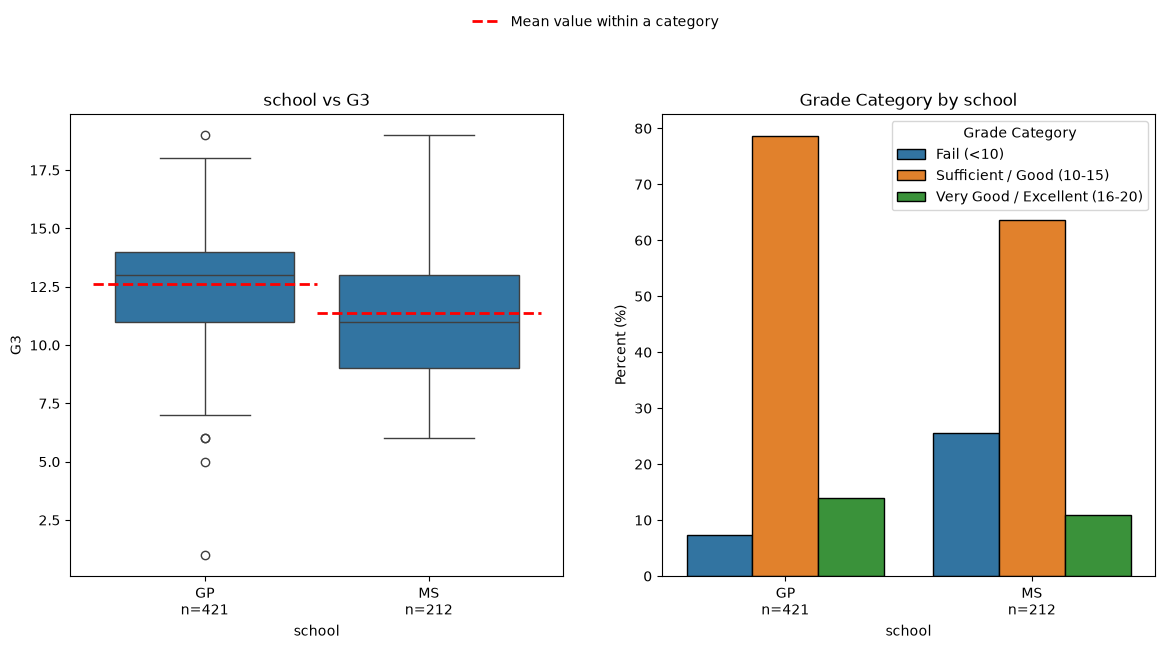

In [39]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 6))
ds.plot_target(
	df=df_por,
	features='school',
	target='G3', 
	display_count=True,
	show_mean=True,
	ax=axes[0]
)

ds.distr_comp(
	df=df_por,
	features='school',
	target='Grade Category',
	display_count=True,
	ax=axes[1]
)

plt.show()

Gabriel Pereira students appear to perform somewhat better than Mousinho da Silveira students. Let's put numbers on this observation.

In [40]:
print(f'eta-squared : {ds.eta_squared(df_por["school"], df_por["G3"]) : .4f}')
groups, _ = ds.get_groups(df=df_por, by='school', columns='G3')
mannwhitneyu_school = mannwhitneyu(*groups)

print(f'Mann-Whitney U-statistic : {mannwhitneyu_school.statistic : .4f}')
print(f'Mann-Whitney p-value : {mannwhitneyu_school.pvalue : .2e}')

eta-squared :  0.0486
Mann-Whitney U-statistic :  58190.5000
Mann-Whitney p-value :  3.19e-10


In [41]:
df_por['Passed'] = df_por['G3'] >= 10
print(f"Failed percentage for GP school : {100 - df_por[df_por['school'] == 'GP']['Passed'].mean() * 100 : .2f}%")
print(f"Failed percentage for MS school : {100 - df_por[df_por['school'] == 'MS']['Passed'].mean() * 100 : .2f}%")

Failed percentage for GP school :  7.36%
Failed percentage for MS school :  25.47%


$\eta^2=0.0486$ means that the school explains about $5\%$ of the variance of the final grade, and the Mann–Whitney test confirms that the grade distributions of the two schools differ ($\text{p-value}\approx3\cdot10^{-10}$).

The difference in failure rates is much more striking than the difference in means: $25.5\%$ of Mousinho da Silveira students fail, compared with $7.4\%$ at Gabriel Pereira, i.e. about 3.5 times as many. And this is after cleaning: if the 14 Mousinho da Silveira students without a final grade (see [Check Outliers](#check-outliers)) are counted as failing, the rate rises to about $30\%$.

The schools also serve different students: about half of Mousinho da Silveira's students live in rural areas ($51\%$), compared with $19\%$ at Gabriel Pereira (see the table below). Part of the gap between the schools may therefore reflect who attends them rather than the schools themselves.

In [42]:
# Share of rural (R) and urban (U) students in each school
pd.crosstab(df_por['school'], df_por['address'], normalize='index').round(3)

address,R,U
school,,
GP,0.185,0.815
MS,0.514,0.486


# 4. Modeling

Let's now build several models to answer *Q2* and *Q3*.

## Linear Regression

First, let's build baseline models to answer *Q2*: linear regressions of the final grade on the mid-year grades.

In [43]:
baseline1_formula = 'G3 ~ G1'
baseline1_res = ols(formula=baseline1_formula, data=df_por).fit()
baseline1_r2 = baseline1_res.rsquared
print(baseline1_r2)

0.7677206858761294


In [44]:
baseline_formula = 'G3 ~ G2 + G1'
baseline_res = ols(formula=baseline_formula, data=df_por).fit()
baseline_r2 = baseline_res.rsquared
print(baseline_r2)

0.8811258847225362


The baseline model that uses only `G1` and `G2` reaches $R^2\approx0.881$: past grades explain about $88\%$ of the variance of the final grade (`G1` alone explains about $77\%$).

Now let's add every other feature one at a time and check whether any of them still carries signal once `G1` and `G2` are taken into account.

In [45]:
other_features = ['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu',
       'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime',
       'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery',
       'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc',
       'Walc', 'health', 'absences']

rows = []

for i in other_features:
	extended_formula = f'{baseline_formula} + {i}'
	extended_res = ols(formula=extended_formula, data=df_por).fit()
	extended_r2 = extended_res.rsquared
	f_test = anova_lm(baseline_res, extended_res)
	rows.append([
		i, 
	    extended_r2 - baseline_r2,
		# share of the variance that G1 and G2 leave unexplained
		(extended_r2 - baseline_r2) / (1 - baseline_r2),
		f_test['Pr(>F)'].iloc[1]
	])

# Compressing results into a DataFrame
ols_results = pd.DataFrame(
	rows,
	columns=['Feature Added', 'R2 improvement', 'partial R2', 'p-value']
)

ols_results['adjusted p-value'] = multipletests(ols_results['p-value'], method='holm')[1]
ols_results = ols_results.sort_values(
	by='p-value'
).reset_index(drop=True)
ols_results.head(10)

,Feature Added,R2 improvement,partial R2,p-value,adjusted p-value
0,age,0.001340,0.011273,0.007601,0.228035
1,failures,0.001086,0.009133,0.016334,0.473681
2,Dalc,0.001038,0.008730,0.018900,0.529205
3,health,0.000821,0.006902,0.036941,0.997400
4,sex,0.000805,0.006772,0.038770,1.000000
5,Walc,0.000644,0.005416,0.064676,1.000000
6,freetime,0.000583,0.004905,0.078749,1.000000
7,traveltime,0.000516,0.004338,0.098317,1.000000
8,higher,0.000511,0.004296,0.099975,1.000000
9,goout,0.000471,0.003961,0.114227,1.000000


Once mid-year grades are known, no single factor adds meaningful information about the final grade. The strongest, `age`, explains only about $1\%$ of the remaining variance, and none of the factors remains significant after correcting for 30 tests (Holm correction).

## Tree-based Models

Now we build simple decision trees to find out which pairs of factors best separate students who pass from those who fail. We start with one-feature trees to get baseline AUC scores that the pairs will be compared with. Categorical features are one-hot encoded, and the dummy columns of each feature are kept together, so each "feature" below is one of the original columns.

In [46]:
def build_groups(X, df_raw):
	# group dummy siblings back under their original column name
	groups = defaultdict(list)
	for col in X.columns:
		origin = col if col in df_raw.columns else col.rsplit('_', 1)[0]
		groups[origin].append(col)
	return dict(groups)


df_tree = df_por.copy()

X, y = df_tree.drop(columns=['G1', 'G2', 'G3', 'Grade Category', 'Passed']), df_tree['Passed']
features = X.columns

# encoding categories (using dummies due to low cardinality)
X = pd.get_dummies(data=X, drop_first=True)
groups = build_groups(X, df_tree)

In [47]:
auc_scores = {}
auc_mean_scores = {}
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=0)
for f in features:
	simple_tree = DecisionTreeClassifier(
		random_state=0,
		max_depth=2
	)
	scores = cross_val_score(
		estimator=simple_tree,
		X=X[groups[f]],
		y=y,
		cv=cv,
		scoring='roc_auc',
	)
	auc_scores[f] = scores
	auc_mean_scores[f] = scores.mean()
# auc_scores

Now we evaluate a two-feature tree for every pair of features and compare each pair with the stronger of its two features.

In [48]:
pairs_res = []
for i in range(len(features)):
	for j in range(i + 1, len(features)):
		f1, f2 = features[i], features[j]
		pair_tree = DecisionTreeClassifier(
			random_state=0,
			max_depth=2
		)
		scores = cross_val_score(
			estimator=pair_tree,
			X=X[groups[f1] + groups[f2]],
			y=y,
			cv=cv,
			scoring='roc_auc',
			n_jobs=-1
		)
		best = f1 if auc_mean_scores[f1] >= auc_mean_scores[f2] else f2
		diff = scores - auc_scores[best]
		pairs_res.append({
			'pair': f'{f1} + {f2}',
			'mean auc': scores.mean(),
			'best single': best,
			'best single mean auc': auc_mean_scores[best],
			'mean auc improvement': diff.mean(),
			'paired win share (%)': (diff > 0).mean() * 100,
		})

In [49]:
pairs_res_df = pd.DataFrame(pairs_res)
print(f'{pairs_res_df.shape[0]} pairs were scanned')

pairs_improved = (
	pairs_res_df[pairs_res_df['paired win share (%)'] >= 95]
	.sort_values('mean auc', ascending=False)
	.reset_index(drop=True)
)

pairs_improved.style.format({
	'mean auc': '{:.3f}',
	'mean auc improvement': '{:+.3f}',
	'best single mean auc': '{:.3f}',
	'paired win share (%)': '{:.2f}'
})


435 pairs were scanned


,pair,mean auc,best single,best single mean auc,mean auc improvement,paired win share (%)
0,school + failures,0.779,failures,0.690,+0.089,98.00
1,school + higher,0.759,school,0.673,+0.086,100.00
2,guardian + failures,0.728,failures,0.690,+0.038,98.00
3,school + famrel,0.714,school,0.673,+0.041,100.00
4,Mjob + higher,0.668,higher,0.632,+0.036,100.00


Each pair was compared with the stronger of its two features fold by fold: all models use the same 50 cross-validation folds (5 folds repeated 10 times with a fixed `random_state`), so on every fold the pair and the single feature are evaluated on exactly the same students. `paired win share (%)` is the percentage of folds in which the pair reached a higher AUC than its stronger feature alone. A pair is considered informative if it wins in at least $95\%$ of the folds. All 435 pairs were scanned, so a few borderline passes are expected by chance: this is a robust ranking heuristic, not a formal significance test.

Five pairs pass this rule:
1. `school` + `failures`
2. `school` + `higher`
3. `guardian` + `failures`
4. `school` + `famrel`
5. `Mjob` + `higher`

The best pairs combine two *different kinds* of information. `failures` describes the student's own academic history and `higher` their motivation, while `school` adds context: the same history or motivation is associated with different outcomes in the two schools, whose failure rates differ strongly (see [Schools Comparison](#schools-comparison)). This is why `school` appears in three of the five pairs.

Consistency and size are different things, though. `Mjob` + `higher` wins in all folds, but only by $+0.036$ AUC, and its overall AUC ($0.668$) is modest. The pair `school` + `failures` is both consistent and the strongest overall (AUC $0.779$, $+0.089$ over `failures` alone).

## Final Tuned Model

As a final, more complex model, we train and tune an `XGBRegressor` that predicts the final grade *without* the mid-year grades, evaluate it, and use permutation importance as another view on feature importance.

In [50]:
df_xgb = df_por.copy()
X, y = df_xgb.drop(columns=['G1', 'G2', 'G3', 'Grade Category', 'Passed']), df_xgb['G3']
# encoding categories (using dummies due to low cardinality)
X = pd.get_dummies(data=X, drop_first=True)

In [51]:
xgb_basic = XGBRegressor(random_state=0, n_jobs=-1)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
xgb_basic.fit(X_train, y_train)
y_pred = xgb_basic.predict(X_test)
print(f'Default R2 score : {r2_score(y_test, y_pred):.5f}')
print(f'Default MAE score: {mean_absolute_error(y_test, y_pred):.3f}')
print(f'Default RMSE score: {root_mean_squared_error(y_test, y_pred):.3f}')

Default R2 score : 0.15797
Default MAE score: 1.847
Default RMSE score: 2.366


In [52]:
xgb = XGBRegressor(random_state=0)
cv_params = {
	'n_estimators' : [5, 10, 50, 75, 100, 130, 170, 200],
	'learning_rate' : [0.01, 0.02, 0.05, 0.075, 0.1, 0.2],
	'max_depth' : list(range(1, 7)),
}

dtr_cv = GridSearchCV(
	estimator=xgb,
	param_grid=cv_params,
	scoring=['r2', 'neg_mean_absolute_error' , 'neg_root_mean_squared_error'],
	refit='r2',
	n_jobs=-1,
	cv=5,
	verbose=1
)

In [53]:
dtr_cv.fit(
	X_train,
	y_train
)

Fitting 5 folds for each of 288 candidates, totalling 1440 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBRegressor(...ree=None, ...)"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'learning_rate': [0.01, 0.02, ...], 'max_depth': [1, 2, ...], 'n_estimators': [5, 10, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","['r2', 'neg_mean_absolute_error', ...]"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'r2'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,

In [54]:
print(dtr_cv.best_params_)
print(dtr_cv.best_score_)

{'learning_rate': 0.2, 'max_depth': 1, 'n_estimators': 170}
0.31152160167694093


In [55]:
model = dtr_cv.best_estimator_
y_pred = model.predict(X_test)
print(f'Tuned R2 score : {r2_score(y_test, y_pred):.5f}')
print(f'Tuned MAE score: {mean_absolute_error(y_test, y_pred):.3f}')
print(f'Tuned RMSE score: {root_mean_squared_error(y_test, y_pred):.3f}')

Tuned R2 score : 0.29122
Tuned MAE score: 1.634
Tuned RMSE score: 2.170


In [56]:
linear_default = LinearRegression(n_jobs=-1)
linear_default.fit(X_train, y_train)
y_pred = linear_default.predict(X_test)
print(f'Linear R2 score : {r2_score(y_test, y_pred):.5f}')
print(f'Linear MAE score: {mean_absolute_error(y_test, y_pred):.3f}')
print(f'Linear RMSE score: {root_mean_squared_error(y_test, y_pred):.3f}')

Linear R2 score : 0.27030
Linear MAE score: 1.673
Linear RMSE score: 2.202


Tuning improved the model's performance on the test set:
$R^2: 0.158 \to 0.291$ (cross-validated $R^2$ on the training set: $0.312$)
$\text{MAE}: 1.847 \to 1.634$
$\text{RMSE}: 2.366 \to 2.170$

The default model overfits: with trees 6 levels deep, it is flexible enough to memorize noise in only 474 training students. The best tuned model uses trees of depth 1 (single splits), which means that it cannot model any interactions between features; it simply adds up the separate contributions of each feature. That is essentially what a linear model does, and indeed a plain linear regression on the same split reaches almost the same result ($R^2=0.270$, $\text{MAE}=1.673$, $\text{RMSE}=2.202$). In other words, this data contains little non-linear structure for a complex model to exploit, and the tuned XGBoost model is roughly equivalent to a linear model. Both results come from a single test set of 159 students, so small differences between them are not meaningful.

Next, we calculate and plot the permutation importance of the features.

In [57]:
def grouped_permutation_importance(model, X, y, groups, n_repeats=10, random_state=0):
	rng = np.random.default_rng(random_state)
	baseline = r2_score(y, model.predict(X))
	out = []
	for name, cols in groups.items():
		for _ in range(n_repeats):
			Xp = X.copy()
			perm = rng.permutation(len(Xp))
			Xp[cols] = Xp[cols].values[perm]
			out.append([name, baseline - r2_score(y, model.predict(Xp))])
	return pd.DataFrame(out, columns=['Feature', 'Permutation Importance']) 

groups = build_groups(X_test, df_por)
imp_grouped = grouped_permutation_importance(model, X_test, y_test, groups)

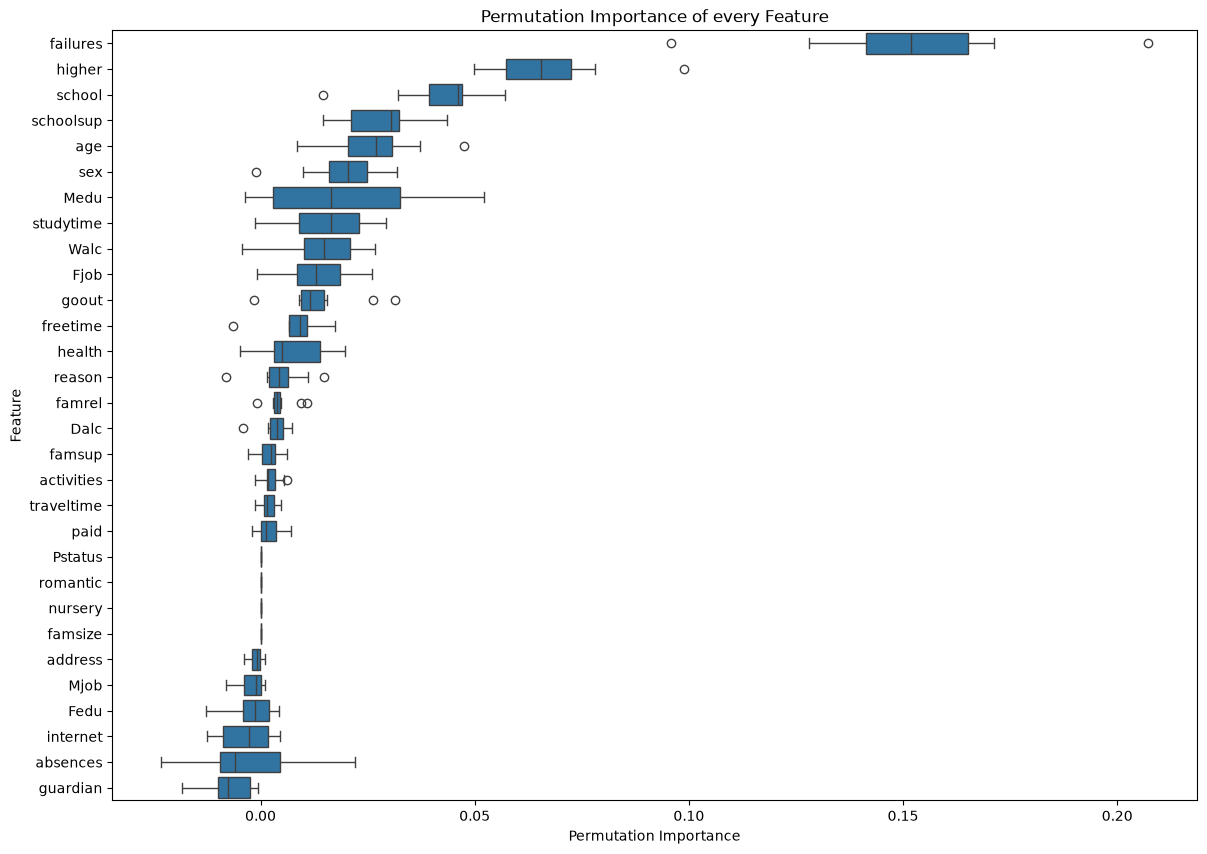

In [58]:
imp_plot_data = imp_grouped.copy()
medians = imp_plot_data.groupby('Feature')['Permutation Importance'].median()
imp_plot_data['median'] = imp_plot_data['Feature'].map(medians)

plt.figure(figsize=(14, 10))
ax = sns.boxplot(
	data=imp_plot_data.sort_values(by='median', ascending=False),
	x='Permutation Importance',
	y='Feature'
)
ax.set_title('Permutation Importance of every Feature')
plt.show()

`failures`, `higher`, `school`, `schoolsup`, `age`, `sex` and `Medu` appear to be the most important features. These results are not very robust, though, because the test set is relatively small.

Finally, let's train a model that also uses the mid-year grades.

In [59]:
X_full = df_por.copy().drop(columns=['G3', 'Grade Category', 'Passed'])
y = df_por['G3']
X_full = pd.get_dummies(data=X_full, drop_first=True)
X_train_full, X_test_full, y_train_full, y_test_full = train_test_split(X_full, y, test_size=0.25, random_state=0)

xgb_full = XGBRegressor(random_state=0)
cv_params_full = {
	'n_estimators' : [5, 10, 50, 75, 100, 130, 170, 200],
	'learning_rate' : [0.01, 0.02, 0.05, 0.075, 0.1, 0.2],
	'max_depth' : list(range(1, 7)),
}

dtr_cv_full = GridSearchCV(
	estimator=xgb_full,
	param_grid=cv_params_full,
	scoring=['r2', 'neg_mean_absolute_error' , 'neg_root_mean_squared_error'],
	refit='r2',
	n_jobs=-1,
	cv=5,
	verbose=1
)

dtr_cv_full.fit(
	X_train_full,
	y_train_full
)

Fitting 5 folds for each of 288 candidates, totalling 1440 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBRegressor(...ree=None, ...)"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'learning_rate': [0.01, 0.02, ...], 'max_depth': [1, 2, ...], 'n_estimators': [5, 10, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","['r2', 'neg_mean_absolute_error', ...]"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'r2'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,

In [60]:
dtr_cv_full.best_params_

{'learning_rate': 0.2, 'max_depth': 1, 'n_estimators': 50}

In [61]:
model = dtr_cv_full.best_estimator_
y_pred_full = model.predict(X_test_full)
print(f'Full data R2 score : {r2_score(y_test_full, y_pred_full):.5f}')
print(f'Full data MAE score: {mean_absolute_error(y_test_full, y_pred_full):.3f}')
print(f'Full data RMSE score: {root_mean_squared_error(y_test_full, y_pred_full):.3f}')

Full data R2 score : 0.80527
Full data MAE score: 0.689
Full data RMSE score: 1.138


In [62]:
# Linear model with G1 and G2 only, trained and tested on the same split as the XGB model
linear_split = LinearRegression().fit(X_train_full[['G1', 'G2']], y_train_full)
y_pred_linear = linear_split.predict(X_test_full[['G1', 'G2']])
print(f'Linear (G1 + G2) R2 score : {r2_score(y_test_full, y_pred_linear):.5f}')
print(f'Linear (G1 + G2) MAE score: {mean_absolute_error(y_test_full, y_pred_linear):.3f}')
print(f'Linear (G1 + G2) RMSE score: {root_mean_squared_error(y_test_full, y_pred_linear):.3f}')

Linear (G1 + G2) R2 score : 0.80803
Linear (G1 + G2) MAE score: 0.728
Linear (G1 + G2) RMSE score: 1.129


With the mid-year grades included, the tuned XGBoost model reaches $R^2\approx0.805$ ($\text{MAE}=0.689$, $\text{RMSE}=1.138$) on the test set, while a linear model that uses only `G1` and `G2`, trained and tested on the same split, reaches $R^2\approx0.808$ ($\text{MAE}=0.728$, $\text{RMSE}=1.129$). The complex model with all features adds nothing over a two-variable linear model. This confirms the answer to *Q2* from a different direction: once mid-year grades are known, the remaining features carry almost no extra information, and a simple linear model is the most appropriate choice for predicting the final grade.

# 5. Conclusions

## Q1. Which single factors matter most?

Both the $R^2/\eta^2$ ranking and the permutation importance of the tuned XGBoost model show that **past failures** are the most informative single factor: $\eta^2\approx0.177$, a median permutation importance of about $0.15$ and Spearman's $\rho=-0.431$.

**The intention to pursue higher education** comes next ($\eta^2\approx0.114$). All "high graders" (final grade 16–20) plan to pursue higher education, and only $10\%$ of the students with such plans fail, compared with $43.75\%$ of those without them.

**Parents' education**, especially the mother's, is also clearly associated with grades (Spearman's $\rho=0.290$ for `Medu`), and it explains most of the apparent link between parents' jobs and grades.

Finally, **the school** is informative as well ($\eta^2\approx0.049$), mainly through the very different failure rates ($25.5\%$ vs $7.4\%$). This result is harder to generalize, because other schools may differ more or less.

## Q2. Once past grades are known, what still carries signal?

Once mid-year grades are known, no other factor adds meaningful information about the final grade. `G1` and `G2` together explain about $88\%$ of its variance (`G1` alone about $77\%$), the strongest additional factor (`age`) explains only about $1\%$ of what remains, and none stays significant after correcting for 30 tests. A tuned XGBoost model with all features does no better than a linear model with `G1` and `G2` alone. Mid-year grades are therefore the information that can be acted on most reliably.

The other features are not useless, though. *Without* any grades, they explain about $27$–$31\%$ of the variance of the final grade (test $R^2=0.291$ for the tuned XGBoost model and $0.270$ for a linear model; cross-validated $R^2=0.312$). That is enough for an early warning signal at the start of the school year, before any grades exist: the pass/fail trees from *Q3* separate passing from failing students with an AUC of $0.78$ using only past failures and the school.

## Q3. Which pairs of factors best separate passing from failing students?

To answer this question, we trained a depth-2 decision tree for every pair of features (435 pairs) and compared each pair with the stronger of its two features on the same 50 cross-validation folds. Five pairs beat their stronger feature in at least $95\%$ of the folds (mean AUC after the colon):

1. `school` + `failures`: $0.779$
2. `school` + `higher`: $0.759$
3. `guardian` + `failures`: $0.728$
4. `school` + `famrel`: $0.714$
5. `Mjob` + `higher`: $0.668$

AUC is the probability that the model ranks a randomly chosen passing student above a randomly chosen failing one ($0.5$ means random guessing, $1$ means perfect separation). The strongest pairs combine the student's own history or motivation (`failures`, `higher`) with context (`school`).

As mentioned in *Q1*, the role of `school` is specific to these two schools and would need to be checked case by case elsewhere.

## Q4. Do paid classes or school support help?

In this data, students who receive extra support from the school ($n=66$) or take paid extra classes ($n=38$) have slightly *lower* final grades than those who don't ($11.45$ vs $12.28$, $\text{p-value}\approx0.017$, and $11.50$ vs $12.23$, $\text{p-value}\approx0.14$, not significant), and the effects are very weak ($\eta^2<0.01$). However, these students already had lower first-period grades, which suggests that support is given to students who struggle. Without data on how these students performed before they started receiving support, this data cannot show whether the support helps.

## Other Findings

### Family Factors

Parents' jobs appear to be related to grades, but for mothers this association is explained by education: mothers who work as teachers or in health care are usually highly educated, and within the same education level their children's grades do not differ by the mother's job. The only exception is fathers who are teachers, whose children score higher even compared with children of equally educated fathers (a small group, $n=32$).

### Educational Factors

Students with internet access at home perform better:

|Internet access at home|Share of "high graders"|Share of failing students|
|-----------------------|-----------------------|-------------------------|
|Yes|0.143|0.122|
|No|0.084|0.175|

This difference is most likely related to family background (urban homes and more educated parents), since it does not appear among rural students.

Longer study time is associated with better performance:
- Study time is positively correlated with grades: Spearman's $\rho=0.264$.
- As study time increases, the share of "high graders" goes up and the share of failing students goes down.

### Social Factors

The association between `freetime` and the final grade (`G3`) is $\cap$-shaped, peaking at level 2, and the same applies to `goout`. Students with some free time and some time with friends do best, while those at either extreme have lower grades.

Alcohol consumption, both on workdays and at weekends, has a negative monotonic association with the final grade:
- `Dalc`: $\rho_D=-0.204$
- `Walc`: $\rho_W=-0.167$

## Limitations

- **Associations, not causes.** The data come from a survey at a single point in time, so none of the findings show that changing a factor would change grades.
- **Self-reported data.** Study time, alcohol consumption, free time and similar features are students' own answers on short scales and may be inaccurate.
- **Two schools in one country.** The data cover two Portuguese secondary schools in the 2005–2006 school year, so the results, especially those about the schools, may not generalize.
- **Small groups.** Some groups are small (for example, 14–17 students with the highest workday alcohol consumption, or 32 children of highly educated fathers who are teachers), so the results for them are uncertain.
- **Dropped students.** 15 students without a final grade (14 of them from Mousinho da Silveira) were removed, which makes that school look somewhat better than it is.

## Recommendations per Audience

1. **For teachers:**
	- Mid-year grades predict the final grade almost perfectly ($R^2\approx0.88$). Act on `G1` and `G2` rather than on students' background.
2. **For administrators:**
	- Mousinho da Silveira students fail about 3.5 times as often as Gabriel Pereira students ($25.5\%$ vs $7.4\%$), and 14 of the 15 students who missed the final exam were from Mousinho da Silveira. This gap deserves a closer look.
3. **For early intervention:**
	- Past failures and no plans for higher education are the clearest risk flags available before any grades exist.
4. **For parents:**
	- The strongest family link is the mother's education level; once it is taken into account, the mother's job adds little.
	- The choice of school is associated with large differences in failure rates, although part of this gap may reflect differences between the schools' students.
	- Among the factors that can change within a school year, study time, alcohol consumption, time spent going out and plans for higher education show the clearest associations with grades.
5. **For students:**
	- Regular study time, plans for higher education and a moderate amount of going out are associated with better grades; drinking alcohol, especially on workdays, is associated with worse ones.